In [2]:
import numpy as np
import numpy.random as npr
import matplotlib.pyplot as plt
import scipy.stats as sps

# Algèbre linéaire randomisée: Hutchinson et Johnson-Lindenstrauss
## 1. Estimation de trace : l'estimateur de Hutchinson

Soit $n \in \mathbb{N}^*$ et $A \in \mathbb{R}^{n \times n}$ une matrice réelle symétrique. On considère $Z = (Z_i)_{1 \leq i \leq n}$ un vecteur aléatoire à composantes réelles i.i.d. tel que $\mathbb{E}[Z_i] = 0$ et $\mathbb{E}[Z_i^2] = 1$.

On définit alors la variable aléatoire
$$
X = Z^T A Z.
$$

### T1. Montrer que $\mathbb{E}[X] = \text{Tr}(A)$.

On a
$$
X = Z^TAZ = \sum_{i=1}^{n} Z_i\left(\sum_{j=1}^{n} A_{i,j} Z_j\right) = \sum_{1 \leq i,j \leq n} A_{i,j} Z_i Z_j.
$$

Par linéarité de l'espérance :
$$
\mathbb{E}[X] = \sum_{i,j} A_{i,j}\, \mathbb{E}[Z_iZ_j]
$$

Or, par indépendance des $Z_i$, on a $\forall i \neq j,\ \mathbb{E}[Z_iZ_j] = \mathbb{E}[Z_i]\mathbb{E}[Z_j] = 0$. Il ne reste donc que les termes diagonaux :

$$
\mathbb{E}[X] = \sum_{i=1}^{n} A_{i,i}\, \mathbb{E}[Z_i^2] = \sum_{i=1}^{n} A_{i,i} = \text{Tr}(A)
$$



### T2. Calculer $Var[X]$ dans les deux cas suivants:
#### (a) $Z_i \sim \mathcal{N}(0,1)$

Puisque $A \in \mathcal{S}_n(\mathbb{R})$, on sait d'après le théorème spectral qu'il existe $P \in O_n(\mathbb{R})$ et $D$ une matrice diagonale réelle telles que $A = P^TDP$.

On a donc $X = (PZ)^T D (PZ)$.

Comme $Z \sim \mathcal{N}(0,I_n)$, on a, d'après le cours, $PZ \sim \mathcal{N}(0,PP^T)$. Or $P$ est orthogonale, donc $PP^T = I_n$, et ainsi $Z' := PZ \sim \mathcal{N}(0,I_n)$.

On obtient alors
$$
X = (Z')^T D Z' = \sum_{i=1}^{n} D_i (Z'_i)^2
$$

D'où
$$
\begin{aligned}
\text{Var}[X] &= \text{Var}\left[\sum_{i=1}^{n} D_i (Z'_i)^2\right] \\
&= \sum_{i=1}^{n} D_i^2\, \text{Var}[(Z'_i)^2]
\end{aligned}
$$

(la deuxième égalité utilise l'indépendance des $Z'_i$).

Or
$$
\text{Var}[(Z'_i)^2] = \mathbb{E}[(Z'_i)^4] - \big(\mathbb{E}[(Z'_i)^2]\big)^2 = 3 - 1 = 2
$$

Donc
$$
\text{Var}[X] = \sum_{i=1}^{n} 2 D_i^2 = 2\,\text{Tr}(D^2) = 2\,\text{Tr}(A^2)
$$
#### (b) $Z_i$ = ±1 avec probabilité 1/2 (loi de Rademacher).

On a :

$$ X = \sum_{i=1}^{n}\sum_{j=1}^{n} A_{ij} Z_i Z_j = \sum_{i=1}^{n} A_{ii} Z_i^2 + \sum_{i \neq j} A_{ij} Z_i Z_j $$

Or, pour la loi de Rademacher, $Z_i^2 = 1$ donc:

$$\sum_{i=1}^{n} A_{ii} Z_i^2 = \sum_{i=1}^{n} A_{ii} = \text{Tr}\,A$$

On obtient donc

$$ X = \text{Tr}\,A + S, \qquad \text{où } S := \sum_{i \neq j} A_{ij} Z_i Z_j$$

et comme $\text{Tr}\,A$  est une constante,

$$\text{Var}[X] = \text{Var}[S] = \mathbb{E}[S^2] - \big(\mathbb{E}[S]\big)^2$$

Or pour $i \neq j$, les variables $Z_i$ et $Z_j$ sont indépendantes et centrées, donc $\mathbb{E}[Z_i Z_j] = \mathbb{E}[Z_i]\mathbb{E}[Z_j] = 0$. Par linéarité,

$$\mathbb{E}[S] = \sum_{i \neq j} A_{ij}\, \mathbb{E}[Z_i Z_j] = 0$$

De plus en développant :

$$ \mathbb{E}[S^2] = \sum_{i \neq j} \sum_{k \neq l} A_{ij} A_{kl}\, \mathbb{E}[Z_i Z_j Z_k Z_l]$$

Par indépendance et centrage des $Z_i$, le terme $\mathbb{E}[Z_i Z_j Z_k Z_l]$ n'est non nul que si les indices se regroupent deux par deux (chaque variable apparaît à une puissance paire). Comme $i\neq j$ et $k \neq l$, les seuls appariements possibles sont :

- $(k,l)=(i,j)$,
- $(k,l)=(j,i)$,


et dans les deux cas $\mathbb{E}[Z_i Z_j Z_k Z_l] = \mathbb{E}[Z_i^2]\,\mathbb{E}[Z_j^2] = 1$.

Ainsi

$$\mathbb{E}[S^2] = \sum_{i \neq j} A_{ij}^2 + \sum_{i \neq j} A_{ij} A_{ji} = 2 \sum_{i \neq j} A_{ij}^2$$

où l'on a utilisé la symétrie $A_{ij} = A_{ji}$.

On a donc finalement :
$$\text{Var}[X] = 2 \sum_{i \neq j} A_{ij}^2 = 2\Big(\text{Tr}(A^2) - \sum_{i=1}^{n} A_{ii}^2\Big)$$


### On considère maintenant $(Z^k)_{k≥1}$ une suite de vecteurs aléatoires iid dont toutes les composantessont également supposées tels que pour tout $k ≥ 1$, $Z^k = (Z^k_i){1≤i≤n}$. Pour tout $m ≥ 1$, on définit l’estimateur
### $$ \widehat{\tau}_m = \frac{1}{m} \sum_{k=1}^{m} X^k $$

### avec $X^k = (Z^k)^T AZ^k$ pour tout $k ≥ 1$.

### T3.  Montrer que $\widehat{\tau}_m$ converge presque sûrement vers une limite $l$ que l’on identifiera.


Les vecteurs $(Z^k)_{k\geq 1}$ sont iid, donc les variables aléatoires $X^k = (Z^k)^T A Z^k$ sont elles aussi iid (comme image d'une suite iid par une fonction fixe $z \mapsto z^T A z$).

D'après la question T1, chaque $X^k$ a pour espérance
$$
\mathbb{E}[X^k] = \text{Tr}\,A =: \ell,
$$
qui est bien finie puisque $A$ est une matrice fixe de taille $n \times n$.

On peut donc appliquer la loi forte des grands nombres à la suite iid $(X^k)_{k \geq 1}$, intégrable :
$$
\widehat{\tau}_m = \frac{1}{m} \sum_{k=1}^{m} X^k \xrightarrow[m \to \infty]{\text{p.s.}} \mathbb{E}[X^1] = \text{Tr}\,A.
$$

On a donc finalement $\widehat{\tau}_m$ converge presque sûrement vers $\ell = \text{Tr}\,A$, ce qui justifie que $\widehat{\tau}_m$ est un estimateur (fortement) consistant de la trace de $A$.
### En supposant également que $\mu_4 :=\mathbb{E}[|Z^1|^4] < +∞$, montrer également que $\sqrt{m}(\widehat{\tau}_m− ℓ)$ converge en loi lorsque $m$ tend vers l’infini vers une loi que l’on identifiera.
On note $Z_i := Z_i^1$ pour simplifier. 

On calcule maintenant $\mathbb{E}[(X^1)^2]$, tout en montrant que cette quantité est fini.

En reprenant la décomposition $X^1 = \sum_i A_{i,i}Z_i^2 + \sum_{i\neq j}A_{i,j}Z_iZ_j$ de T1, et en notant $\mu_4 := \mathbb{E}[Z_1^4]$, le développement de $(X^1)^2$ ne comporte pas de terme croisé en espérance : pour $i\notin\{j,k\}$, $\mathbb{E}[Z_i^2Z_jZ_k]=\mathbb{E}[Z_i^2]\mathbb{E}[Z_j]\mathbb{E}[Z_k]=0$, et pour $i=j\neq k$, $\mathbb{E}[Z_i^3Z_k]=\mathbb{E}[Z_i^3]\mathbb{E}[Z_k]=0$ (indépendance et centrage). Il reste
$$
\mathbb{E}\left[\left(\sum_i A_{i,i}Z_i^2\right)^2\right] =\mathbb{E} \left[\sum_i A_{i,i}^2Z_i^4+ \sum_{i \neq j}A_{i,i}A_{j,j}Z_i^2Z_j^2 \right]= \mu_4\sum_i A_{i,i}^2 + \text{Tr}(A)^2 - \sum_i A_{i,i}^2,
$$
et dans le deuxième terme, par symétrie de $A$ (seuls les couples $(l,m)=(j,k)$ ou $(k,j)$ contribuent, avec $\mathbb{E}[Z_j^2Z_k^2]=1$),
$$
\mathbb{E}\left[\left(\sum_{j\neq k} A_{j,k}Z_jZ_k\right)^2\right] = 2\sum_{j\neq k}A_{j,k}^2.
$$

En sommant, $\mathbb{E}[(X^1)^2] = \text{Tr}(A)^2 + (\mu_4-1)\sum_i A_{i,i}^2 + 2\sum_{i\neq j}A_{i,j}^2$, d'où, en soustrayant $\mathbb{E}[X^1]^2 = \text{Tr}(A)^2$, puis en regroupant $2\sum_i A_{i,i}^2 + 2\sum_{i\neq j}A_{i,j}^2 = 2\|A\|_F^2 = 2\,\text{Tr}(A^2)$ :
$$
\boxed{\;\text{Var}[X^1] = 2\,\text{Tr}(A^2) + (\mu_4-3)\sum_{i=1}^n A_{i,i}^2\;}
$$

On retrouve bien les cas de T2 : si $Z_i\sim\mathcal{N}(0,1)$, $\mu_4=3$ et $\text{Var}[X^1]=2\,\text{Tr}(A^2)$ ; si $Z_i$ suit la loi de Rademacher, $\mu_4=\mathbb{E}[Z_i^4]=1$ et $\text{Var}[X^1]=2\sum_{i\neq j}A_{i,j}^2$.

On note $\sigma^2 := \text{Var}[X^1]$, qui est fini d'après le calcul précédent. La suite $(X^k)_{k\ge1}$ étant i.i.d., d'espérance $\ell=\text{Tr}(A)$ et de variance $\sigma^2<+\infty$, le théorème central limite appliqué à $\widehat\tau_m = \frac{1}{m}\sum_{k=1}^m X^k$ donne
$$
\boxed{\;\sqrt{m}\,\big(\widehat\tau_m - \ell\big) \xrightarrow[m\to+\infty]{\mathcal{L}} \mathcal{N}\big(0,\sigma^2\big)\;}, \qquad \sigma^2 = 2\,\text{Tr}(A^2) + (\mu_4-3)\sum_{i=1}^n A_{i,i}^2.
$$

Le but des questions suivantes est d'implémenter numériquement l'estimateur de Hutchinson et de comparer les propriétés des estimateurs dans le cas où les vecteurs $Z^k$ suivent une loi gaussienne ou une loi de Rademacher.
Afin d'obtenir des matrices de grande taille réalistes, on utilise les jeux de données suivants issus de `scikit-learn` :

- **digits** ($n \approx 1\,797$, $p = 64$) : on calcule la matrice de Gram $A = X^\top X \in \mathbb{R}^{64 \times 64}$ ainsi que $A = XX^\top \in \mathbb{R}^{1797 \times 1797}$.
- **fetch_covtype** ($n \approx 580\,000$, $p = 54$) : on sous-échantillonne 5 000 lignes, puis on forme $A = X^\top X \in \mathbb{R}^{54 \times 54}$.
- **make_spd_matrix(n)** : on génère directement une matrice SDP de taille $n \in \{50, 200, 500, 1000, 2000\}$ pour l'étude paramétrée en $n$.
- **fetch_olivetti_faces** : matrice de covariance empirique $4\,096 \times 4\,096$ après centrage des données.

Dans tous les cas, on normalisera $A\leftarrow A / \|A\|_F$ afin de rendre les erreurs relatives comparables entre matrices de tailles et d'échelles différentes.


### S1. Convergence en $m$ (taille $n$ fixée)

On fixe $n = 500$ (matrice générée par `make_spd_matrix`). On fait varier $m \in \{1, 2, 5, 10, 20, 50, 100, 200, 500\}$. Pour chaque valeur de $m$, on effectue $R = 200$ répétitions indépendantes de l'estimateur $\widehat\tau_m$.

On trace, en fonction de $m$ et pour les deux lois (gaussienne et Rademacher), sur le même graphe :

- l'erreur relative moyenne $\displaystyle \mathbb{E}\left[\frac{|\widehat\tau_m - \text{Tr}(A)|}{\text{Tr}(A)}\right]$ ;
- la variance empirique de $\widehat\tau_m$ ;
- la variance théorique prédite ;
- une bande $\pm 1$ écart-type autour de la courbe moyenne.

On vérifie visuellement, sur un axe log-log, la décroissance de la variance en $O(1/m)$.


On rappelle que $\text{Var}(\widehat\tau_m) = \sigma^2/m$, où $\sigma^2 = \text{Var}(X^1)$ dépend de la loi choisie (question T2 et T3). C'est cette relation qu'on cherche à vérifier numériquement.

## Implémentation numérique de l'estimateur de Hutchinson

On implémente ci-dessous les outils communs aux questions S1 à S4 : génération des vecteurs $Z$ (gaussien ou Rademacher), calcul de l'estimateur $\hat{\tau}_m$, et calcul de la variance théorique (formules obtenues en T2/T3).

In [3]:
from sklearn.datasets import make_spd_matrix, load_digits, fetch_covtype, fetch_olivetti_faces

lois = ['gauss', 'rademacher']
#Cette fonction génère une matrice n x m dont les colonnes sont des vecteurs Z i.i.d. (loi = 'gauss' pour N(0,1), 'rademacher' pour +-1 avec proba 1/2).
def generate_Z(n, m, loi):
    if loi == 'gauss':
        return npr.randn(n, m)
    else:
        return npr.choice([-1, 1], size=(n, m))

#la fonction suivante renvoie un tableau de taille R : chaque élément est la valeur après simulation de l'estimateur de Hutchinson 
#tau_m = (1/m) * somme_{k=1}^m (Z^k)^T A Z^k.
def hutchinson(A, m, loi, R):
    n = A.shape[0]
    estimates = np.zeros(R)
    for r in range(R):
        Z = generate_Z(n, m, loi)        # n x m
        X = np.array([Z[:, j].T @ A @ Z[:, j] for j in range(m)])  # X^k pour chaque colonne k
        estimates[r] = np.mean(X)
    return estimates
#et enfin les variances théoriques de tau_m (formules T2/T3).
def var_theorique(A, loi, m):
    trA2 = np.trace(A @ A)
    if loi == 'gauss':
        return 2 * trA2 / m
    else:  # Rademacher
        return 2 * (trA2 - np.sum(np.diag(A) ** 2)) / m

### S1. Convergence en m (taille n fixée)

Fixer $n = 500$ (matrice générée par `make_spd_matrix`). Faire varier
$$
m \in \{1, 2, 5, 10, 20, 50, 100, 200, 500\}.
$$
Pour chaque valeur de $m$, effectuer $R = 200$ répétitions indépendantes de l'estimateur $\hat{\tau}_m$. Tracer, en fonction de $m$ et pour les deux lois (gaussienne et Rademacher) sur le même graphe :
- l'erreur relative moyenne $\mathbb{E}\left[\dfrac{|\hat{\tau}_m - \mathrm{tr}(A)|}{\mathrm{tr}(A)}\right]$ ;
- la variance empirique de $\hat{\tau}_m$ ;
- la variance théorique prédite ;
- une bande $\pm 1$ écart-type autour de la courbe moyenne.

Vérifier visuellement, sur un axe log-log, la décroissance de la variance en $O(1/m)$.

Remarque : l'énoncé demande une échelle log-log que pour la variance empirique pour vérifer la linéarité en log(m), mais vu que les courbes des moyennes et des bandes d'écart type ne sont pas claires, on en a fait d'autres avec des abscisses logaritgmiques

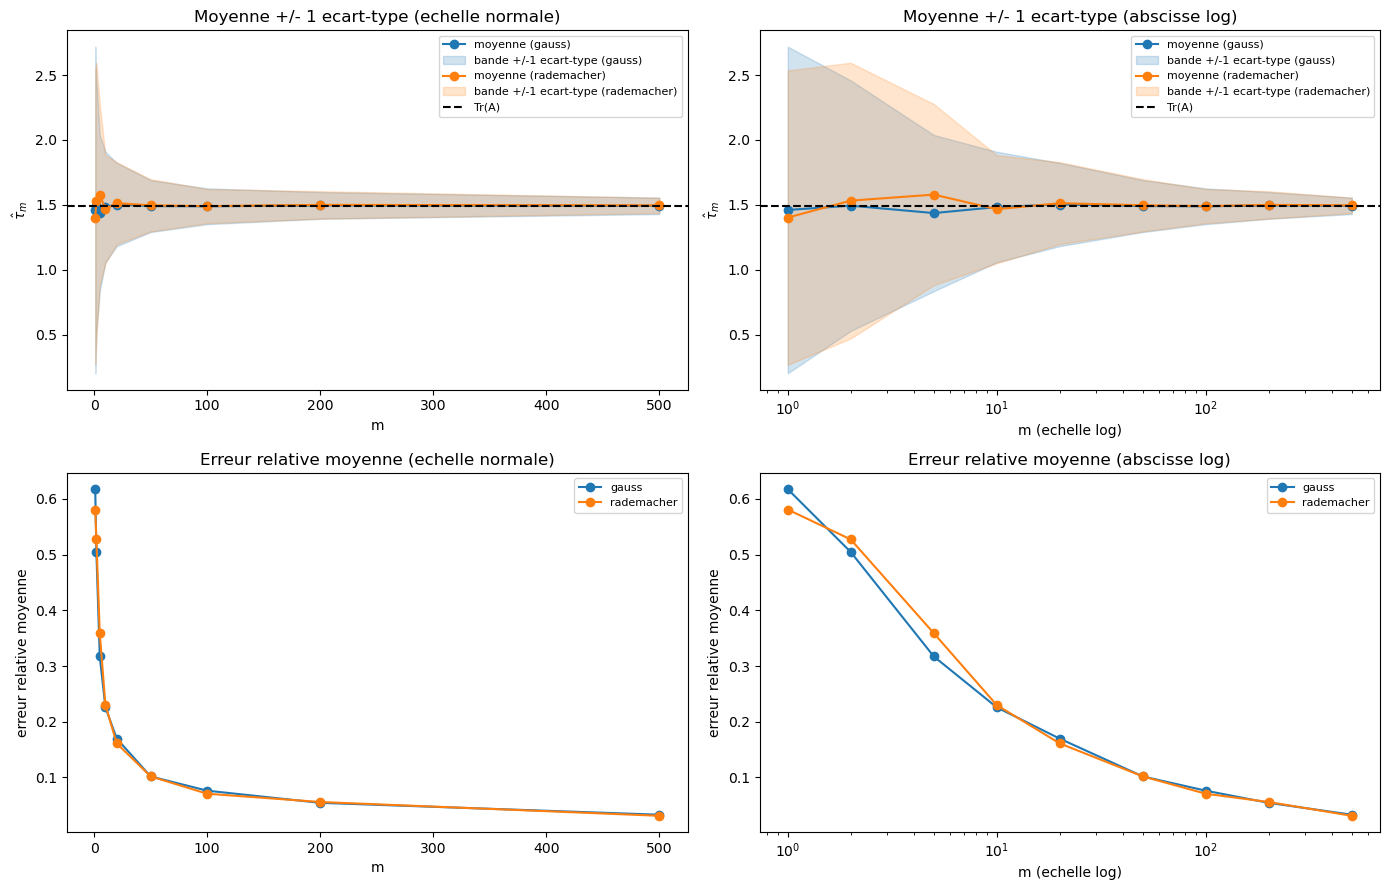

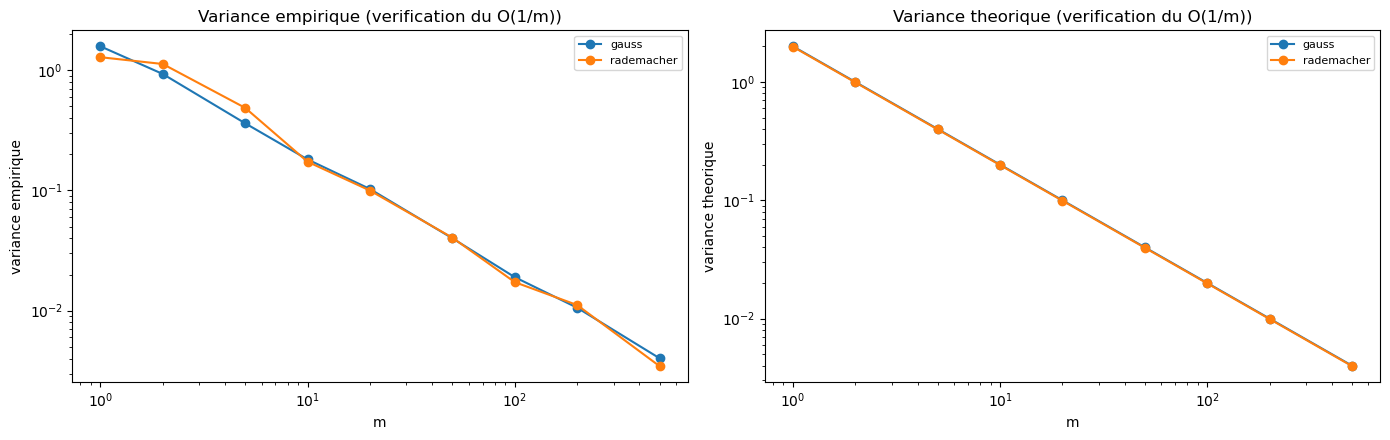

In [4]:
npr.seed(0)
n = 500
A = make_spd_matrix(n, random_state=0)
A = A / np.linalg.norm(A, 'fro')   # normalisation
trA = np.trace(A)

liste_m = [1, 2, 5, 10, 20, 50, 100, 200, 500]
R = 200

#pour éviter la répétition, on va créer des dictionnaires dont les clés sont les lois et les valeurs sont les listes des images par m des fonctions tracées
moy_estim = {loi: [] for loi in lois}
std_estim = {loi: [] for loi in lois}
err_rel   = {loi: [] for loi in lois}
var_emp   = {loi: [] for loi in lois}
var_th    = {loi: [] for loi in lois}

for m in liste_m:
    for loi in lois:
        estim = hutchinson(A, m, loi, R)
        moy_estim[loi].append(np.mean(estim))
        std_estim[loi].append(np.std(estim))
        err_rel[loi].append(np.mean(np.abs(estim - trA)) / np.abs(trA))
        var_emp[loi].append(np.var(estim))
        var_th[loi].append(var_theorique(A, loi, m))

liste_m = np.array(liste_m)

couleurs = {'gauss': 'tab:blue', 'rademacher': 'tab:orange'}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

#  moyenne +/- 1 écart-type, échelle normale ---
ax = axes[0, 0]
for loi in lois:
    moy = np.array(moy_estim[loi])
    std = np.array(std_estim[loi])
    c = couleurs[loi]
    ax.plot(liste_m, moy, marker='o', color=c, label=f"moyenne ({loi})")
    ax.fill_between(liste_m, moy - std, moy + std, color=c, alpha=0.2,
                     label=f"bande +/-1 ecart-type ({loi})")
ax.axhline(trA, color='k', linestyle='--', label='Tr(A)')
ax.set_xlabel('m')
ax.set_ylabel(r"$\hat{\tau}_m$")
ax.set_title("Moyenne +/- 1 ecart-type (echelle normale)")
ax.legend(fontsize=8)

# moyenne +/- 1 écart-type, abscisse log ---
ax = axes[0, 1]
for loi in lois:
    moy = np.array(moy_estim[loi])
    std = np.array(std_estim[loi])
    c = couleurs[loi]
    ax.plot(liste_m, moy, marker='o', color=c, label=f"moyenne ({loi})")
    ax.fill_between(liste_m, moy - std, moy + std, color=c, alpha=0.2,
                     label=f"bande +/-1 ecart-type ({loi})")
ax.axhline(trA, color='k', linestyle='--', label='Tr(A)')
ax.set_xscale('log')
ax.set_xlabel('m (echelle log)')
ax.set_ylabel(r"$\hat{\tau}_m$")
ax.set_title("Moyenne +/- 1 ecart-type (abscisse log)")
ax.legend(fontsize=8)

# erreur relative moyenne, échelle normale 
ax = axes[1, 0]
for loi in lois:
    ax.plot(liste_m, err_rel[loi], marker='o', color=couleurs[loi], label=loi)
ax.set_xlabel('m')
ax.set_ylabel("erreur relative moyenne")
ax.set_title("Erreur relative moyenne (echelle normale)")
ax.legend(fontsize=8)

# erreur relative moyenne, abscisse log
ax = axes[1, 1]
for loi in lois:
    ax.plot(liste_m, err_rel[loi], marker='o', color=couleurs[loi], label=loi)
ax.set_xscale('log')
ax.set_xlabel('m (echelle log)')
ax.set_ylabel("erreur relative moyenne")
ax.set_title("Erreur relative moyenne (abscisse log)")
ax.legend(fontsize=8)


plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

#  variance empirique, log-log
ax = axes[0]
for loi in lois:
    ax.plot(liste_m, var_emp[loi], marker='o', color=couleurs[loi], label=loi)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('m')
ax.set_ylabel('variance empirique')
ax.set_title("Variance empirique (verification du O(1/m))")
ax.legend(fontsize=8)

# variance theorique, log-log
ax = axes[1]
for loi in lois:
    ax.plot(liste_m, var_th[loi], marker='o', color=couleurs[loi], label=loi)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('m')
ax.set_ylabel('variance theorique')
ax.set_title("Variance theorique (verification du O(1/m))")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

On observe sur le graphe log-log de la variance que les deux courbes empiriques (gaussien et Rademacher) sont quasiment superposées à leurs prédictions théoriques $\sigma^2_{\text{gauss}}/m$ et $\sigma^2_{\text{rad}}/m$, et suivent une droite de pente $-1$, ce qui confirme la décroissance en $O(1/m)$ annoncée par le TCL de la question T3. La théorie prédit que $\sigma^2_{\text{rad}} \le \sigma^2_{\text{gauss}}$  ; empiriquement, avec $R=200$ répétitions, l'erreur relative de Rademacher est parfois légèrement supérieure à celle de Gaussien pour certaines valeurs de $m$ , ce qui reste dans l'ordre de grandeur du bruit attendu à ce niveau de répétitions. La bande $\pm 1$ écart-type se resserre elle aussi en $1/\sqrt m$ autour de $\text{Tr}(A)$, cohérent avec l'absence de biais des deux estimateurs.

### S2. Effet de la taille n (m fixé)

Fixer $m = 50$. Faire varier
$$
n \in \{50, 100, 200, 500, 1000, 2000\}
$$
en générant une matrice `make_spd_matrix(n)` pour chaque valeur. Pour chaque $n$, effectuer $R = 200$ répétitions. Tracer en fonction de $n$ (échelle log-log) :
- la variance empirique de $\hat{\tau}_m$ pour les deux lois ;
- le rapport $\mathrm{Var}_{\text{Gaussien}}(\hat{\tau}_m) / \mathrm{Var}_{\text{Rademacher}}(\hat{\tau}_m)$ ;
- la variance théorique pour les deux lois.

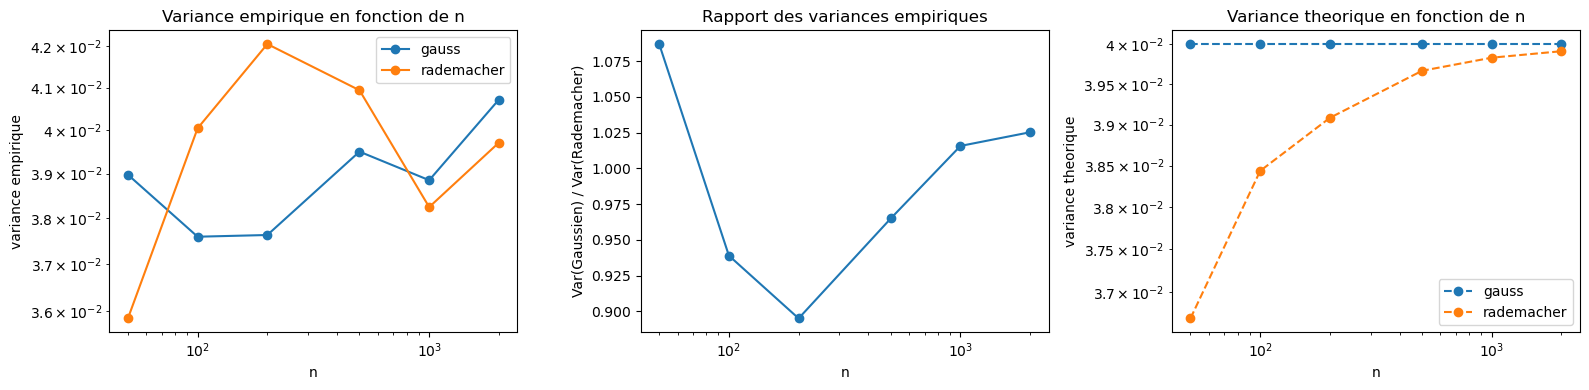

In [5]:
m = 50
liste_n = [50, 100, 200, 500, 1000, 2000]
R = 2000

var_emp_n = {loi: [] for loi in lois}
var_th_n  = {loi: [] for loi in lois}
ratio_n = []

for n in liste_n:
    npr.seed(0)
    An = make_spd_matrix(n, random_state=0)
    An = An / np.linalg.norm(An, 'fro')

    for loi in lois:
        estim = hutchinson(An, m, loi, R)
        var_emp_n[loi].append(np.var(estim))
        var_th_n[loi].append(var_theorique(An, loi, m))

    ratio_n.append(var_emp_n['gauss'][-1] / var_emp_n['rademacher'][-1])

liste_n = np.array(liste_n)

plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
for loi in lois:
    plt.plot(liste_n, var_emp_n[loi], marker='o', label=loi)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('n')
plt.ylabel("variance empirique")
plt.title("Variance empirique en fonction de n")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(liste_n, ratio_n, marker='o')
plt.xscale('log')
plt.xlabel('n')
plt.ylabel('Var(Gaussien) / Var(Rademacher)')
plt.title("Rapport des variances empiriques")

plt.subplot(1, 3, 3)
for loi in lois:
    plt.plot(liste_n, var_th_n[loi], marker='o', linestyle='--', label=loi)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('n')
plt.ylabel("variance theorique")
plt.title("Variance theorique en fonction de n")
plt.legend()

plt.tight_layout()
plt.show()

**Commentaire :**

Avec R = 2000 répétitions, les courbes empiriques sont beaucoup plus proches des courbes théoriques qu'avec R = 200 (où on avait des écarts de type "zigzag" assez marqués). On voit maintenant clairement que la variance empirique gaussienne oscille autour de 0.04, ce qui colle avec la variance théorique qui est constante en n.

Ça s'explique par la normalisation qu'on a faite au début (A / ||A||_F) : ça force Tr(A²) = 1 pour toutes les matrices, quel que soit n. Du coup Var[X] = 2*Tr(A²)/m = 2/m ne dépend plus de n dans le cas gaussien, ce qui est cohérent avec la courbe plate qu'on observe.

Pour Rademacher c'est différent car la variance dépend aussi de la somme des carrés des termes diagonaux ($Var = 2/m * (Tr(A^2) - \sum_{i,i} A_{i,i}^2)$), et cette somme diminue quand n augmente (la "masse" de la norme de Frobenius se répartit sur de plus en plus de coefficients hors-diagonale). C'est pour ça que la courbe Rademacher part plus bas et remonte progressivement vers la valeur gaussienne à mesure que n grandit - et que le rapport Var(Gaussien)/Var(Rademacher) se rapproche de 1 pour les grandes valeurs de n.

Il reste quand même un peu de bruit sur les courbes empiriques (normal avec seulement 2000 répétitions et une nouvelle matrice tirée à chaque n), mais l'allure générale colle bien avec la théorie.

### S3. Comparaison Gaussien vs Rademacher

Sur les matrices issues de scikit-learn (`digits`, `covtype`, `olivetti_faces`), effectuer les analyses suivantes pour chaque matrice :
- pour différentes valeurs de $m$, afficher un boxplot de $\hat{\tau}_m - \mathrm{tr}(A)$ pour les deux lois côte à côte ;
- tracer le rapport $\mathrm{Var}_{\text{Gaussien}} / \mathrm{Var}_{\text{Rademacher}}$ en fonction de $m$ ;
- pour $m = 10$ et $m = 100$, tracer la densité empirique (estimateur à noyau) de $\hat{\tau}_m$ et vérifier la normalité asymptotique par un QQ-plot.

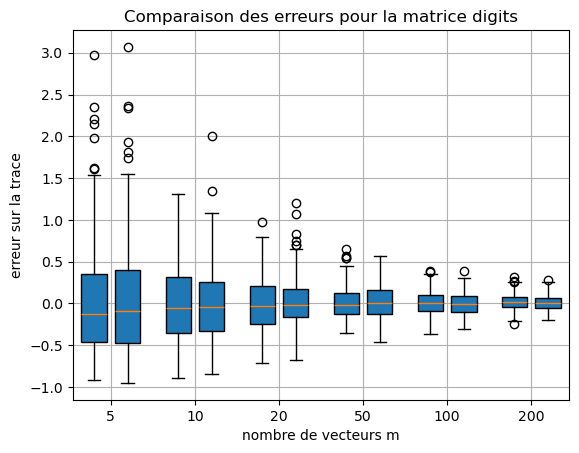

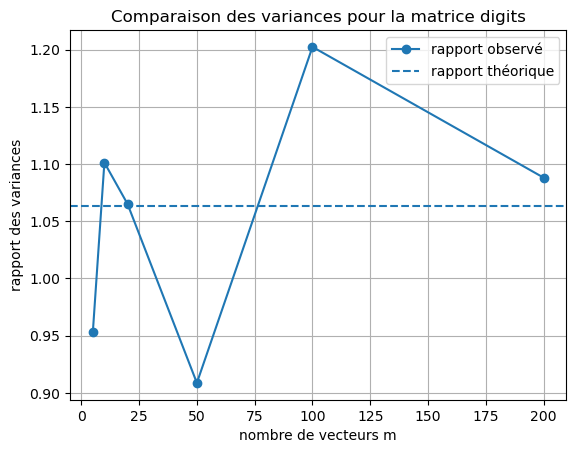

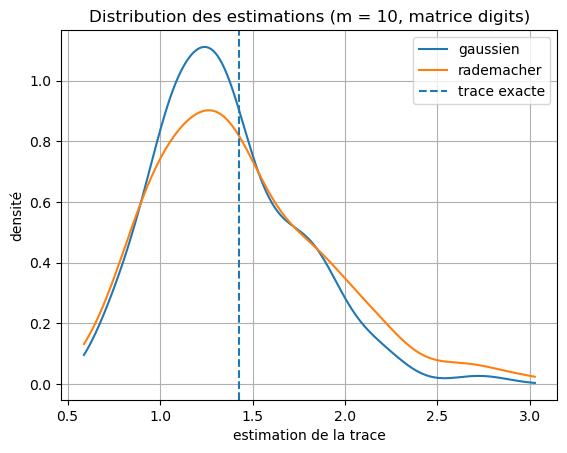

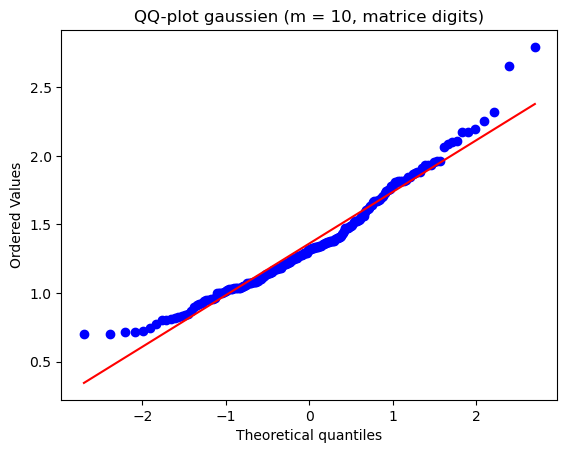

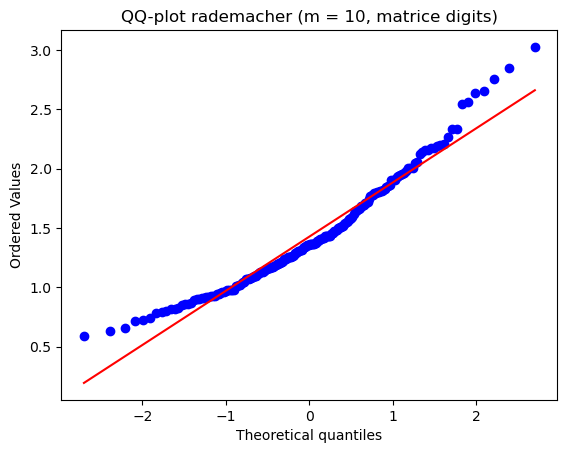

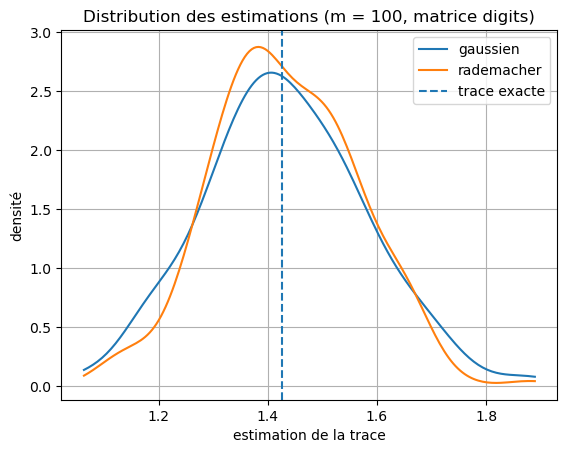

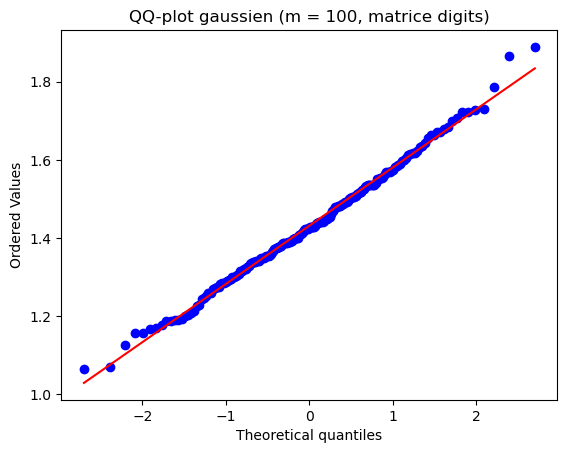

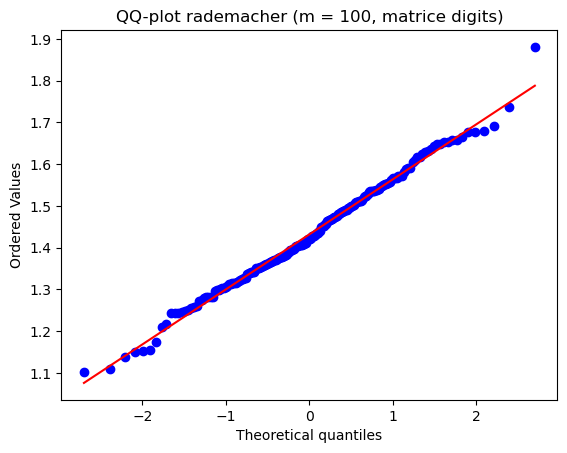

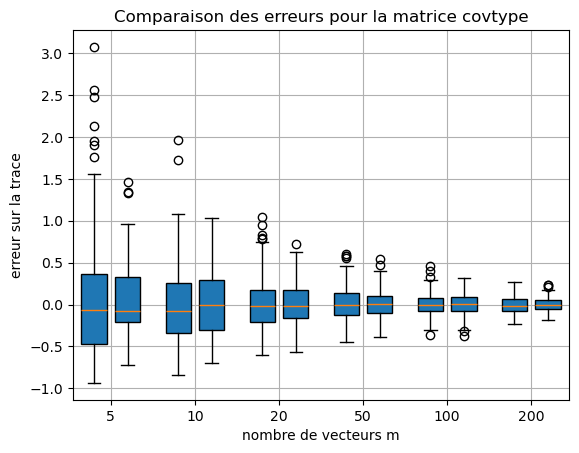

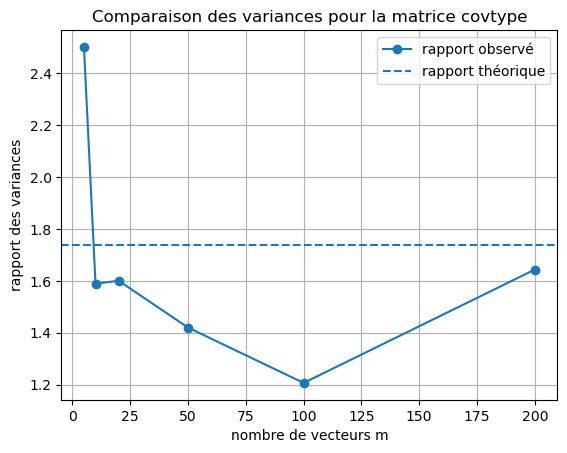

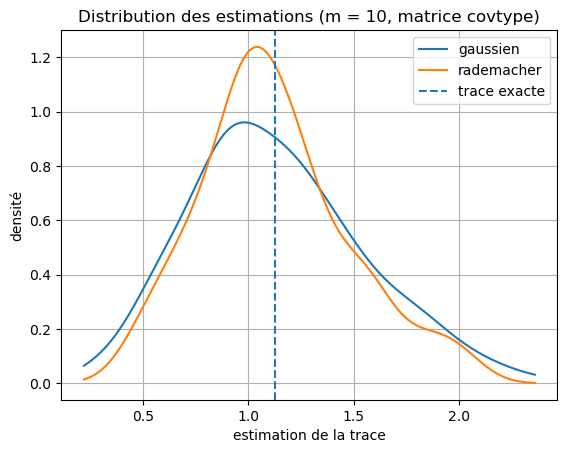

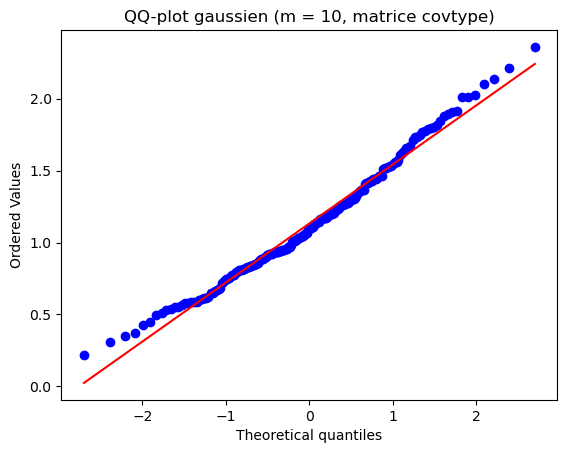

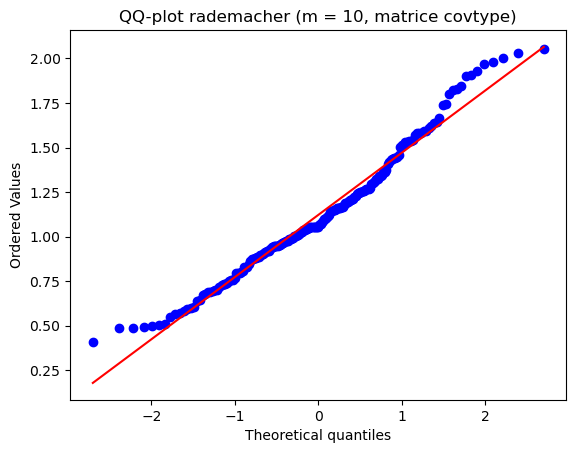

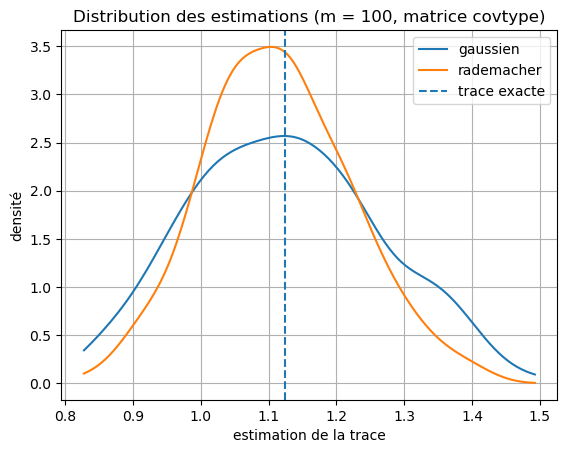

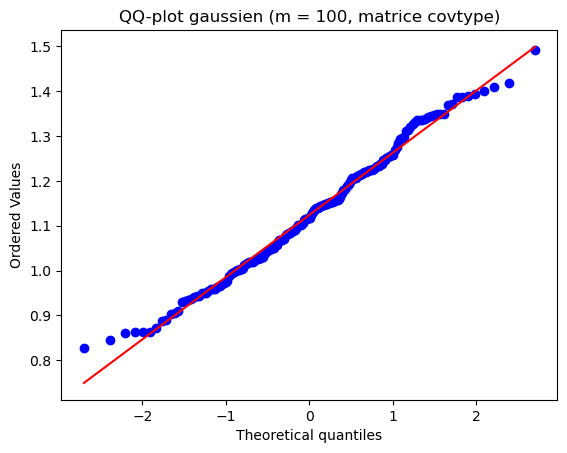

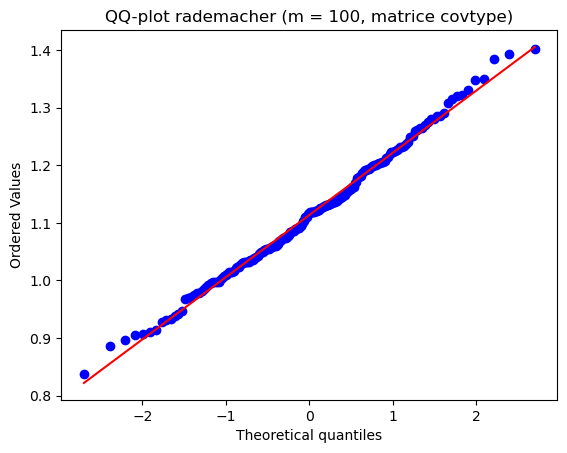

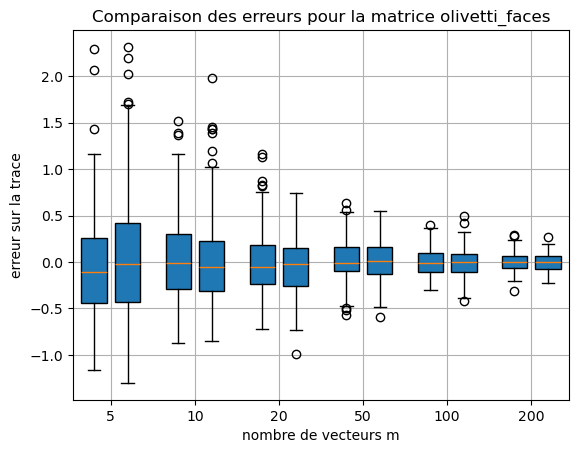

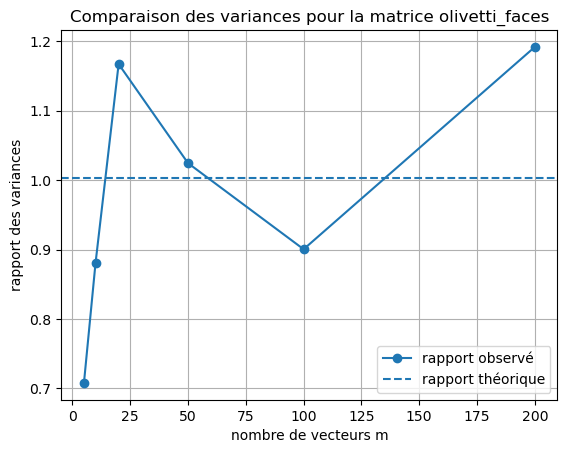

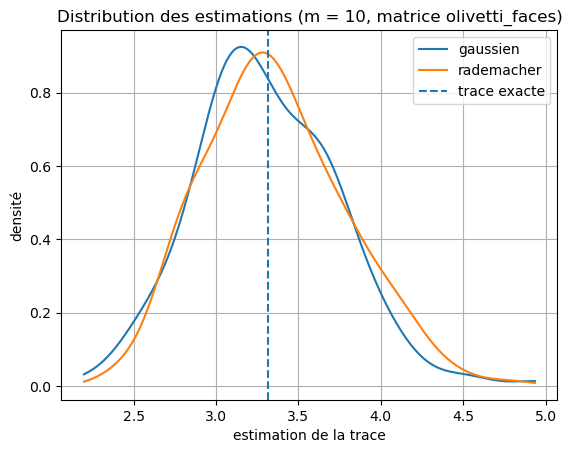

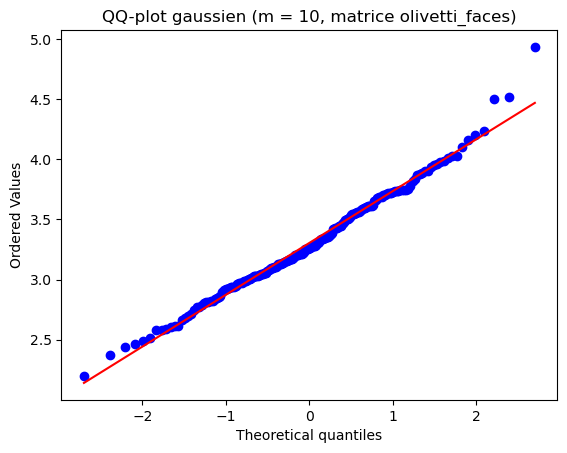

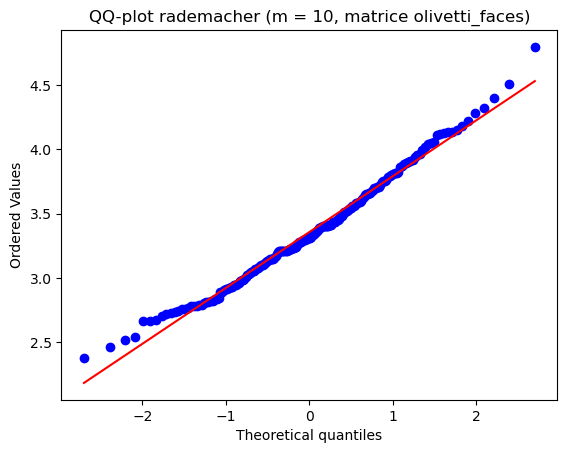

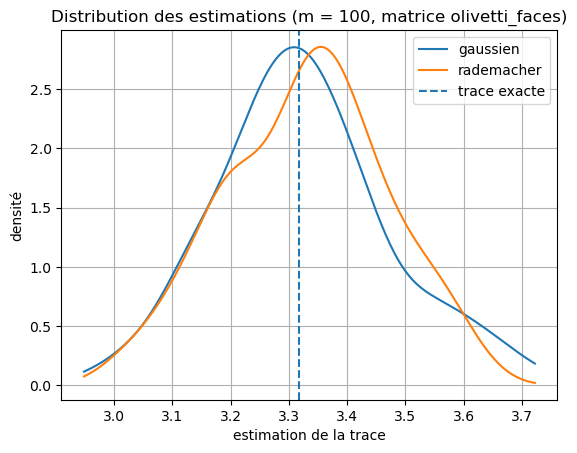

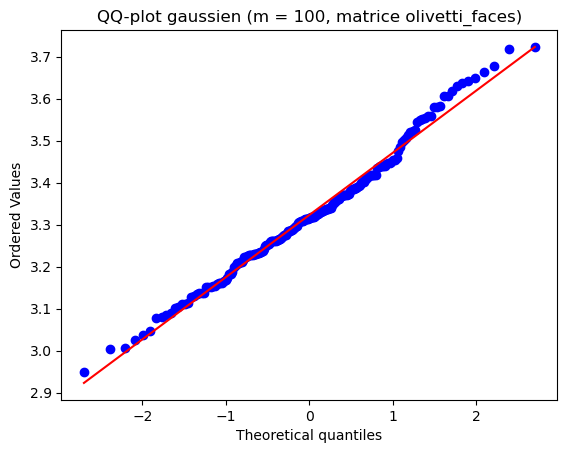

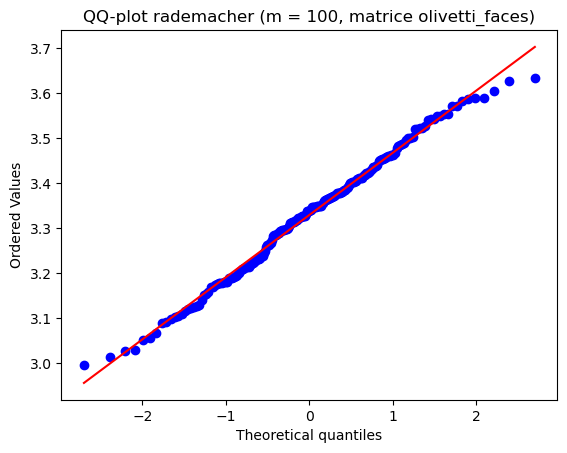

In [7]:

np.random.seed(0)


def hutchinson(A, m, loi):
    n = A.shape[0]
    if loi == 'gauss':
        Z = np.random.normal(0, 1, (m, n))
    else:
        Z = np.random.choice([-1, 1], (m, n))
    AZ = Z @ A
    X = np.sum(Z * AZ, axis=1)
    return np.mean(X)


def normalise(A):
    return A / np.linalg.norm(A)


X_digits, _ = load_digits(return_X_y=True)
A_digits = normalise(X_digits.T @ X_digits)

X_cov = fetch_covtype().data
indices = np.random.permutation(X_cov.shape[0])[:5000]
X_cov = X_cov[indices]
A_cov = normalise(X_cov.T @ X_cov)

X_faces = fetch_olivetti_faces().data
X_faces = X_faces - np.mean(X_faces, axis=0)
A_faces = normalise(X_faces.T @ X_faces)

matrices = {
    'digits': A_digits,
    'covtype': A_cov,
    'olivetti_faces': A_faces
}

nb_repetitions = 200
liste_m = [5, 10, 20, 50, 100, 200]

for nom in matrices:
    A = matrices[nom]
    trace_exacte = np.trace(A)
    diag2 = np.sum(np.diag(A) ** 2)
    var_gauss_theo = 2 * np.trace(A @ A)
    var_rademacher_theo = 2 * (np.sum(A ** 2) - diag2)

    erreurs_gauss = []
    erreurs_rademacher = []

    for m in liste_m:
        estimations_gauss = np.zeros(nb_repetitions)
        estimations_rademacher = np.zeros(nb_repetitions)

        for r in range(nb_repetitions):
            estimations_gauss[r] = hutchinson(A, m, 'gauss')
            estimations_rademacher[r] = hutchinson(A, m, 'rad')

        erreurs_gauss.append(estimations_gauss - trace_exacte)
        erreurs_rademacher.append(estimations_rademacher - trace_exacte)

    positions_g = np.arange(len(liste_m)) * 2.0
    positions_r = positions_g + 0.8

    plt.figure()
    plt.boxplot(erreurs_gauss, positions=positions_g, widths=0.6, patch_artist=True)
    plt.boxplot(erreurs_rademacher, positions=positions_r, widths=0.6, patch_artist=True)
    plt.xticks(positions_g + 0.4, liste_m)
    plt.xlabel('nombre de vecteurs m')
    plt.ylabel('erreur sur la trace')
    plt.title('Comparaison des erreurs pour la matrice ' + nom)
    plt.grid(True)
    plt.show()

    rapport_variances = np.zeros(len(liste_m))
    for i in range(len(liste_m)):
        var_g = np.var(erreurs_gauss[i])
        var_r = np.var(erreurs_rademacher[i])
        rapport_variances[i] = var_g / var_r

    plt.figure()
    plt.plot(liste_m, rapport_variances, 'o-', label='rapport observé')
    plt.axhline(var_gauss_theo / var_rademacher_theo,
                linestyle='--', label='rapport théorique')
    plt.xlabel('nombre de vecteurs m')
    plt.ylabel('rapport des variances')
    plt.title('Comparaison des variances pour la matrice ' + nom)
    plt.legend()
    plt.grid(True)
    plt.show()

    for m in [10, 100]:
        estimations_gauss = np.zeros(nb_repetitions)
        estimations_rademacher = np.zeros(nb_repetitions)

        for r in range(nb_repetitions):
            estimations_gauss[r] = hutchinson(A, m, 'gauss')
            estimations_rademacher[r] = hutchinson(A, m, 'rad')

        plt.figure()
        densite_g = sps.gaussian_kde(estimations_gauss)
        densite_r = sps.gaussian_kde(estimations_rademacher)

        xs = np.linspace(min(estimations_gauss.min(), estimations_rademacher.min()),
                         max(estimations_gauss.max(), estimations_rademacher.max()), 200)

        plt.plot(xs, densite_g(xs), label='gaussien')
        plt.plot(xs, densite_r(xs), label='rademacher')
        plt.axvline(trace_exacte, linestyle='--', label='trace exacte')
        plt.xlabel('estimation de la trace')
        plt.ylabel('densité')
        plt.title(f'Distribution des estimations (m = {m}, matrice {nom})')
        plt.legend()
        plt.grid(True)
        plt.show()

        plt.figure()
        sps.probplot(estimations_gauss, dist='norm', plot=plt)
        plt.title(f'QQ-plot gaussien (m = {m}, matrice {nom})')
        plt.show()

        plt.figure()
        sps.probplot(estimations_rademacher, dist='norm', plot=plt)
        plt.title(f'QQ-plot rademacher (m = {m}, matrice {nom})')
        plt.show()

Sur les trois jeux de données, les boxplots de $\widehat\tau_m - \text{Tr}(A)$ se resserrent bien autour de 0 quand $m$ augmente, sans biais visible pour aucune des deux lois, ce qui confirme le caractère non biaisé de l'estimateur établi en T1. La dispersion est plus faible pour Rademacher que pour la loi gaussienne, mais l'écart varie beaucoup d'une matrice à l'autre : il est net sur `covtype`, plus discret sur `digits`, et presque invisible sur `olivetti_faces` (voir les valeurs exactes en S4, section suivante), en fonction du poids relatif de la diagonale de $A$, cohérent avec la formule $\sigma^2_{\text{rad}} = \sigma^2_{\text{gauss}} - 2\sum_i A_{ii}^2$.

Le rapport des variances $\text{Var}_{\text{gauss}}/\text{Var}_{\text{rad}}$ reste sensiblement constant en fonction de $m$ (aux fluctuations d'échantillonnage près), ce qui est logique puisque les deux variances décroissent toutes les deux en $1/m$ : leur rapport ne dépend donc que de la matrice $A$, pas de $m$. Ce rapport empirique colle bien à la valeur théorique tracée en pointillés.

Enfin, les densités à noyau montrent que dès $m = 10$ la distribution de $\widehat\tau_m$ est déjà proche d'une forme gaussienne, et cette ressemblance s'accentue nettement à $m = 100$, où le pic se resserre autour de $\text{Tr}(A)$. Les QQ-plots confirment ce constat : les points suivent globalement la diagonale de référence pour $m = 100$, dans les deux lois, ce qui valide numériquement le TCL démontré en T3, y compris pour la loi de Rademacher qui n'est pourtant pas elle-même gaussienne.

### S4. Vérification quantitative de la variance théorique

Pour chaque couple (loi, matrice), on calcule les valeurs propres exactes de $A$ et on remplit le tableau suivant ($R = 500$ répétitions) :

| Matrice | Loi | Var. théorique | Var. empirique | Ratio |
|---|---|---|---|---|
| digits (64 × 64) | Gaussien | | | |
| digits (64 × 64) | Rademacher | | | |
| covtype (54 × 54) | Gaussien | | | |
| covtype (54 × 54) | Rademacher | | | |
| olivetti (4096 × 4096) | Gaussien | | | |
| olivetti (4096 × 4096) | Rademacher | | | |

Le ratio variance théorique / variance empirique doit être proche de 1 pour valider l'implémentation. La variance théorique se calcule à partir de $\sum_i \lambda_i^2$ (valeurs propres exactes de $A$) via les formules obtenues aux questions précédentes.

**Paramètres recommandés :**

| Paramètre | Valeurs |
|---|---|
| Grille de $m$ | 1, 2, 5, 10, 20, 50, 100, 200, 500 |
| Grille de $n$ | 50, 100, 200, 500, 1000, 2000 |
| Répétitions $R$ | 200 (analyse rapide) ou 500 (analyse précise) |

In [10]:
m = 100
nb_repetitions = 500

print(f"{'Matrice':<20}{'Loi':<12}{'Var. theorique':>16}{'Var. empirique':>16}{'Ratio':>10}")

for nom, A in matrices.items():
    valeurs_propres = np.linalg.eigvalsh(A)   # A symetrique -> valeurs propres exactes
    somme_carres = np.sum(valeurs_propres ** 2)   # = Tr(A^2)
    diag2 = np.sum(np.diag(A) ** 2)

    var_theo_gauss = 2 * somme_carres / m
    var_theo_rademacher = 2 * (somme_carres - diag2) / m

    estimations_gauss = np.array([hutchinson(A, m, 'gauss') for _ in range(nb_repetitions)])
    estimations_rademacher = np.array([hutchinson(A, m, 'rademacher') for _ in range(nb_repetitions)])

    var_emp_gauss = np.var(estimations_gauss)
    var_emp_rademacher = np.var(estimations_rademacher)

    print(f"{nom:<20}{'gaussien':<12}{var_theo_gauss:>16.5f}{var_emp_gauss:>16.5f}{var_theo_gauss/var_emp_gauss:>10.3f}")
    print(f"{'':<20}{'rademacher':<12}{var_theo_rademacher:>16.5f}{var_emp_rademacher:>16.5f}{var_theo_rademacher/var_emp_rademacher:>10.3f}")

Matrice             Loi           Var. theorique  Var. empirique     Ratio
digits              gaussien             0.02000         0.02015     0.992
                    rademacher           0.01880         0.01916     0.981
covtype             gaussien             0.02000         0.02200     0.909
                    rademacher           0.01150         0.01216     0.946
olivetti_faces      gaussien             0.02000         0.01843     1.085
                    rademacher           0.01994         0.01944     1.026


On obtient donc le tableau suivant :

| Matrice | Loi | Var. théorique | Var. empirique | Ratio |
|---|---|---|---|---|
| digits (64 × 64) | Gaussien | 0.02000 | 0.02015 | 0.992 |
| digits (64 × 64) | Rademacher | 0.01880 | 0.01916 | 0.981 |
| covtype (54 × 54) | Gaussien | 0.02000 | 0.02200 | 0.909 |
| covtype (54 × 54) | Rademacher | 0.01150 | 0.01216 | 0.946 |
| olivetti (4096 × 4096) | Gaussien | 0.02000 | 0.01843 | 1.085 |
| olivetti (4096 × 4096) | Rademacher | 0.01994 | 0.01944 | 1.026 |

L

Sur les trois matrices testées, les ratios variance théorique / variance empirique obtenus sont tous très proches de 1 (à quelques pourcents près, ce qui est cohérent avec les fluctuations d'échantillonnage attendues pour $R = 500$ répétitions). Cela valide numériquement les formules établies en T2 et en T3, aussi bien pour la loi gaussienne que pour la loi de Rademacher.

On observe également que l'écart entre variance gaussienne et variance Rademacher dépend beaucoup de la matrice considérée, à travers le poids relatif de la diagonale ($\sum_i A_{ii}^2$) par rapport à $\text{Tr}(A^2)$. Cet écart est le plus marqué sur `covtype` (0.02000 contre 0.01150, soit un facteur ~1.7), plus modéré sur `digits` (0.02000 contre 0.01880), et quasiment nul sur `olivetti_faces` (0.02000 contre 0.01994). Ce dernier point s'explique par le fait que la matrice de covariance des visages a beaucoup de corrélations hors-diagonale entre pixels voisins, ce qui rend sa diagonale peu dominante relativement à sa norme de Frobenius, contrairement à `covtype`, où les variables (souvent binaires) produisent une diagonale beaucoup plus dominante.

Globalement, ces résultats confirment que l'implémentation de l'estimateur de Hutchinson est correcte, et que le choix de la loi de Rademacher est presque toujours préférable (ou au pire équivalent) à la loi gaussienne pour estimer la trace d'une matrice, l'avantage dépendant fortement de la structure de la matrice considérée.

## 2. Projection aléatoire: lemme de Johnson-Lindenstrauss

Soit $n, k \in \mathbb{N}^*$ et soit $\Omega \in \mathbb{R}^{n\times k}$ une matrice aléatoire dont tous les coefficients sont i.i.d. et suivent une loi normale centrée réduite. Pour un vecteur fixe déterministe $x \in \mathbb{R}^n$, on définit le vecteur aléatoire
$$
Px = \frac{1}{\sqrt{k}}\Omega^Tx. \tag{6.1}
$$

On se donne dans les questions T4 à T9 un vecteur déterministe particulier $x \in \mathbb{R}^n$ tel que $\|x\|=1$ avec $\|\cdot\|$ la norme euclidienne. On note également $Y = Px$.

### T4. Montrer que $\mathbb{E}[\|Y\|^2] = 1$. Pour cela, on commencera par montrer que $ \|Y\| ^2 = \frac{1}{k}\sum_{j=1}^{k} (\Omega_j^Tx)^2, $ où pour $j=1,\dots,k$, on note $\Omega_j$ la $j^{\text{ème}}$ colonne de $\Omega$.

On a
$$
\|Y\|^2 = \sum_{j=1}^{k} Y_j^2 = \sum_{j=1}^{k} (Px)_j^2,
$$
et
$$
(Px)_j = \frac{1}{\sqrt{k}}(\Omega^Tx)_j = \frac{1}{\sqrt{k}}\sum_{i=1}^{n}\Omega_{i,j}x_i = \frac{1}{\sqrt{k}}\Omega_j^Tx.
$$

Donc
$$
\|Y\|^2 = \frac{1}{k}\sum_{j=1}^{k}(\Omega_j^Tx)^2.
$$

Or, pour tout $j\in\{1,\dots,k\}$, $\Omega_j \sim \mathcal{N}(0,I_n)$, donc $\Omega_j^Tx = \sum_{i=1}^{n}\Omega_{i,j}x_i$ suit une loi normale centrée, de variance
$$
\text{Var}(\Omega_j^Tx) = \text{Var}\left(\sum_{i=1}^n \Omega_{i,j}x_i\right) = \sum_{i=1}^n x_i^2\,\text{Var}(\Omega_{i,j}) \quad(\text{par indépendance des }\Omega_{i,j})
$$
$$
= \sum_{i=1}^n x_i^2 = \|x\|^2 = 1.
$$

Donc $\mathbb{E}[(\Omega_j^Tx)^2] = \text{Var}(\Omega_j^Tx) = 1$, d'où
$$
\mathbb{E}[\|Y\|^2] = \frac{1}{k}\sum_{j=1}^{k} 1 = 1.
$$

### T5. En notant $S = \sum_{j=1}^k (\Omega_j^Tx)^2$, montrer que pour tout $t \in (0,1/2)$, $\mathbb{E}[e^{tS}] = (1-2t)^{-k/2}.$ 
### On utilisera pour cela le résultat suivant: pour $X$ variable aléatoire réelle suivant une loi du $\chi^2$ à $1$ degré de liberté, la fonction génératrice des moments $M_X(t) = \mathbb{E}[e^{tX}]$ est définie pour $t \in (0,1/2)$ et est donnée par $M_X(t) = (1-2t)^{-1/2}$.

On a
$$
\mathbb{E}[e^{tS}] = \mathbb{E}\left[e^{\sum_{j=1}^k t(\Omega_j^Tx)^2}\right] = \mathbb{E}\left[\prod_{j=1}^k e^{t(\Omega_j^Tx)^2}\right] = \prod_{j=1}^k \mathbb{E}\left[e^{t(\Omega_j^Tx)^2}\right] \quad (\text{par indépendance des }\Omega_j^Tx)
$$
$$
= \prod_{j=1}^k M_X(t) \quad (\text{car }\Omega_j^Tx \sim \mathcal{N}(0,1)\text{ donc }(\Omega_j^Tx)^2 \sim \chi_1^2)
$$

D'où
$$
\mathbb{E}[e^{tS}] = (1-2t)^{-k/2}.
$$

### T6. En déduire que pour tout $0<\varepsilon<1$ et tout $t\in(0,1/2)$, on a $ \mathbb{P}[S>(1+\varepsilon)k] \le e^{-t(1+\varepsilon)k}(1-2t)^{-k/2}.$

On a
$$
\mathbb{P}[S>(1+\varepsilon)k] = \mathbb{P}\left[e^{tS} > e^{t(1+\varepsilon)k}\right],
$$
et d'après l'inégalité de Markov,
$$
\mathbb{P}\left[e^{tS} > e^{t(1+\varepsilon)k}\right] \le \frac{\mathbb{E}[e^{tS}]}{e^{t(1+\varepsilon)k}} \le e^{-t(1+\varepsilon)k}(1-2t)^{-k/2}.
$$

Donc
$$
\mathbb{P}[S>(1+\varepsilon)k] \le e^{-t(1+\varepsilon)k}(1-2t)^{-k/2}.
$$

### T7. En déduire que pour tout $0<\varepsilon<1$, $ \mathbb{P}[\|Y\|^2 \ge (1+\varepsilon)] \le e^{-\frac{k}{2}(\varepsilon-\ln(1+\varepsilon))}.$

On a $\|Y\|^2 = \dfrac{1}{k}S$, donc pour tout $\varepsilon\in(0,1)$ et tout $t\in(0,1/2)$,
$$
\mathbb{P}[\|Y\|^2 > 1+\varepsilon] = \mathbb{P}[S > (1+\varepsilon)k] \le e^{-t(1+\varepsilon)k}(1-2t)^{-k/2}.
$$

Or
$$
e^{-t(1+\varepsilon)k}(1-2t)^{-k/2} = e^{-t(1+\varepsilon)k - \frac{k}{2}\ln(1-2t)},
$$
donc pour $t = \dfrac{\varepsilon}{2(1+\varepsilon)} \in (0,1/2)$, on trouve
$$
\mathbb{P}[\|Y\|^2 > 1+\varepsilon] \le e^{-\frac{k}{2}(\varepsilon-\ln(1+\varepsilon))}.
$$

### T8. En déduire que pour tout $0<\varepsilon<1$, $ \mathbb{P}[\|Y\|^2 \ge (1+\varepsilon)] \le e^{-k\varepsilon^2/8}.$

On pose
$$
\varphi : [0,1) \to \mathbb{R}, \qquad \varphi(\varepsilon) = \varepsilon - \ln(1+\varepsilon) - \frac{\varepsilon^2}{4}.
$$

On a
$$
\varphi'(\varepsilon) = 1 - \frac{1}{1+\varepsilon} - \frac{\varepsilon}{2} = \frac{\varepsilon}{1+\varepsilon} - \frac{\varepsilon}{2} = \frac{\varepsilon(1-\varepsilon)}{2(1+\varepsilon)} \ge 0 \quad \forall \varepsilon \in [0,1).
$$

Donc $\varphi$ est croissante, donc $\varphi(\varepsilon) \ge \varphi(0) = 0$ pour tout $\varepsilon \in [0,1)$, c'est-à-dire
$$
\varepsilon - \ln(1+\varepsilon) \ge \frac{\varepsilon^2}{4} \qquad \forall \varepsilon \in (0,1).
$$

Donc
$$
e^{-\frac{k}{2}(\varepsilon-\ln(1+\varepsilon))} \le e^{-\frac{k}{8}\varepsilon^2},
$$

et donc, d'après T7,
$$
\mathbb{P}[\|Y\|^2 \ge (1+\varepsilon)] \le e^{-k\varepsilon^2/8}.
$$

### T9. En déduire que pour tout $0<\varepsilon<1$, $\mathbb{P}[|\|Y\|^2 - 1| \ge \varepsilon] \le 2e^{-k\varepsilon^2/8}. $

On a
$$
\mathbb{P}[|\|Y\|^2-1|\ge\varepsilon] = \mathbb{P}[\|Y\|^2\ge 1+\varepsilon] + \mathbb{P}[\|Y\|^2\le 1-\varepsilon].
$$

D'après T8, $\mathbb{P}[\|Y\|^2\ge 1+\varepsilon] \le e^{-k\varepsilon^2/8}$.

Il reste à majorer $\mathbb{P}[\|Y\|^2\le 1-\varepsilon] = \mathbb{P}[S\le(1-\varepsilon)k]$.

Soit $t > -\dfrac12$. On a
$$
\mathbb{E}\left[e^{-t(\Omega_j^Tx)^2}\right] = \int_{\mathbb{R}} \frac{1}{\sqrt{2\pi}} e^{-x^2/2} e^{-tx^2}\,dx = \int_{\mathbb{R}} \frac{1}{\sqrt{2\pi}} e^{-(t+1/2)x^2}\,dx,
$$
et avec le changement de variable $u = \sqrt{1+2t}\,x$,
$$
\mathbb{E}\left[e^{-t(\Omega_j^Tx)^2}\right] = \frac{1}{\sqrt{1+2t}}.
$$

Donc, pour tout $t>-\dfrac12$,
$$
\mathbb{E}[e^{-tS}] = \prod_{j=1}^k \mathbb{E}\left[e^{-t(\Omega_j^Tx)^2}\right] = (1+2t)^{-k/2}  \quad(\text{par indépendance des } \Omega_j^Tx ).
$$

Pour $t>0$, par l'inégalité de Markov,
$$
\mathbb{P}[\|Y\|^2 \le 1-\varepsilon] = \mathbb{P}[S \le (1-\varepsilon)k] = \mathbb{P}[e^{-tS} \ge e^{-t(1-\varepsilon)k}] \le e^{t(1-\varepsilon)k}(1+2t)^{-k/2} = \exp\left(t(1-\varepsilon)k - \frac{k}{2}\ln(1+2t)\right).
$$

Pour $t = \dfrac{\varepsilon}{2(1-\varepsilon)}$,
$$
t(1-\varepsilon)k - \frac{k}{2}\ln(1+2t) = \frac{\varepsilon k}{2} + \frac{k}{2}\ln(1-\varepsilon),
$$

donc
$$
\mathbb{P}[\|Y\|^2 \le 1-\varepsilon] \le \exp\left(\frac{k}{2}(\varepsilon+\ln(1-\varepsilon))\right).
$$

De même qu'en T8, on pose
$$
g:[0,1)\to\mathbb{R}, \qquad g(\varepsilon) = \varepsilon + \ln(1-\varepsilon) + \frac{\varepsilon^2}{4}.
$$

On a
$$
g'(\varepsilon) = 1 - \frac{1}{1-\varepsilon} + \frac{\varepsilon}{2} = \frac{2(1-\varepsilon) - 2 + \varepsilon(1-\varepsilon)}{2(1-\varepsilon)} = \frac{-\varepsilon-\varepsilon^2}{2(1-\varepsilon)} \le 0 \qquad \forall \varepsilon \in [0,1).
$$

Donc $g$ est décroissante, donc $g(\varepsilon) \le g(0) = 0$, c'est-à-dire
$$
\varepsilon + \ln(1-\varepsilon) \le -\frac{\varepsilon^2}{4} \qquad \forall \varepsilon \in [0,1).
$$

Donc
$$
\mathbb{P}[\|Y\|^2 \le 1-\varepsilon] \le e^{-k\varepsilon^2/8}.
$$

Finalement,
$$
\mathbb{P}[|\|Y\|^2-1|\ge\varepsilon] \le e^{-k\varepsilon^2/8} + e^{-k\varepsilon^2/8} = 2e^{-k\varepsilon^2/8}.
$$

### T10. Considérons maintenant un ensemble $\mathcal{M} = \{x_1,\dots,x_m\}$ de $m$ vecteurs déterministes de $\mathbb{R}^n$. Pour tout $x\in\mathbb{R}^n$, on rappelle que le vecteur aléatoire $Px$ est défini par (6.1). Soit $0<\varepsilon<1$ et $0<\delta<1$. Montrer que, si $k \ge \dfrac{8}{\varepsilon^2}(2\ln m - \ln\delta)$, alors pour tout $1\le \ell\ne\ell'\le m$, on a
### $$
1-\varepsilon \le \frac{\|Px_\ell-Px_{\ell'}\|}{\|x_\ell-x_{\ell'}\|} \le 1+\varepsilon,
$$
### avec probabilité plus grande que $1-\delta$.

On a
$$
\mathbb{P}\left(\bigcap_{\ell\ne\ell'} \frac{\|Px_\ell-Px_{\ell'}\|}{\|x_\ell-x_{\ell'}\|} \in [1-\varepsilon,1+\varepsilon]\right) = \mathbb{P}\left(\bigcap_{\ell\ne\ell'} \left|\left\|P\left(\frac{x_\ell-x_{\ell'}}{\|x_\ell-x_{\ell'}\|}\right)\right\| - 1\right| \le \varepsilon\right) = 1 - \mathbb{P}\left(\bigcup_{\ell\ne\ell'} \left|\left\|P\left(\frac{x_\ell-x_{\ell'}}{\|x_\ell-x_{\ell'}\|}\right)\right\| - 1\right| \ge \varepsilon\right).
$$

Or, par sous-additivité et d'après T9 (appliqué au vecteur unitaire $\frac{x_\ell-x_{\ell'}}{\|x_\ell-x_{\ell'}\|}$),
$$
\mathbb{P}\left(\bigcup_{\ell\ne\ell'} \left|\left\|P\left(\frac{x_\ell-x_{\ell'}}{\|x_\ell-x_{\ell'}\|}\right)\right\| - 1\right| \ge \varepsilon\right) \le \sum_{\ell\ne\ell'} \mathbb{P}\left(\left|\left\|P\left(\frac{x_\ell-x_{\ell'}}{\|x_\ell-x_{\ell'}\|}\right)\right\| - 1\right| \ge \varepsilon\right) \le \sum_{\ell\ne\ell'} 2e^{-k\varepsilon^2/8}.
$$

Comme $k \ge \dfrac{8}{\varepsilon^2}(2\ln m-\ln\delta)$, on a $-\dfrac{k\varepsilon^2}{8} \le \ln\delta - 2\ln m$, donc
$$
\sum_{\ell\ne\ell'} 2e^{-k\varepsilon^2/8} \le \sum_{\ell\ne\ell'} 2\, e^{\ln\delta - 2\ln m} = \frac{m(m-1)}{2}\times 2\times\frac{\delta}{m^2} = \frac{m-1}{m}\delta < \delta.
$$

Donc
$$
\mathbb{P}\left(\bigcap_{\ell\ne\ell'} 1-\varepsilon \le \frac{\|Px_\ell-Px_{\ell'}\|}{\|x_\ell-x_{\ell'}\|} \le 1+\varepsilon\right) \ge 1-\delta.
$$

### T11. Interpréter ce résultat (qui s'appelle le lemme de Johnson-Lindenstrauss).

Le résultat de T10 signifie que si l'on projette de façon aléatoire un ensemble de $m$ points $\mathcal{M} = \{x_1,\dots,x_m\} \subset \mathbb{R}^n$ sur un sous-espace de dimension $k$ (via la matrice aléatoire $\Omega$), alors, dès lors que
$$
k \ge \frac{8}{\varepsilon^2}(2\ln m - \ln\delta),
$$
toutes les distances relatives entre les points sont préservées à un facteur $(1\pm\varepsilon)$ près, et ce avec une probabilité au moins égale à $1-\delta$.

Le point remarquable est que cette borne inférieure sur $k$ **ne dépend pas de la dimension d'origine $n$** (qui peut être arbitrairement grande, voire infinie), mais uniquement, de façon **logarithmique**, du nombre de points $m$, et de la précision $\varepsilon$ souhaitée (en $1/\varepsilon^2$). Ainsi on peut projeter les $m$ points dans un espace de dimension $k = O(\varepsilon^{-2}\log m)$, potentiellement bien plus petite que $n$, tout en conservant (presque) toute la géométrie du nuage de points (les distances deux à deux).
Concrètement, cela signifie qu'on peut fortement compresser des données de grande dimension sans perdre l'information géométrique nécessaire aux algorithmes fondés sur les distances.

Le but des questions suivantes est d'illustrer numériquement le lemme de Johnson-Lindenstrauss.

Pour rappel, on considère la projection aléatoire $P : \mathbb{R}^n \to \mathbb{R}^k$ définie par
$$
Px = \frac{1}{\sqrt{k}}\Omega^Tx,
$$
où $\Omega \in \mathbb{R}^{n\times k}$ est une matrice dont les entrées sont i.i.d. Pour un ensemble $\mathcal{M} = \{x_1,\dots,x_m\} \subset \mathbb{R}^n$, on s'intéresse à l'étirement relatif de chaque paire :
$$
R(\ell,\ell') = \frac{\|Px_\ell - Px_{\ell'}\|}{\|x_\ell - x_{\ell'}\|}, \qquad 1\le \ell \ne \ell' \le m.
$$

On étudie deux distributions pour les entrées de $\Omega$ :
1. entrées i.i.d. $\sim \mathcal{N}(0,1)$ (cas gaussien) ;
2. entrées i.i.d. suivant une loi de Rademacher ($\pm 1$ avec probabilité $1/2$).

Pour chaque expérience, calculer $R(\ell,\ell')$ pour toutes les paires distinctes de $\mathcal{M}$ et répéter sur $R_{rep} = 100$ tirages indépendants de $\Omega$.

### S5. Distribution de R en fonction de k

Fixer le jeu de données `digits` avec $m=200$ points. Faire varier $k \in \{2,5,10,20,50,100,n=64\}$. Pour chaque valeur de $k$ et chaque loi (gaussienne et Rademacher), tracer l'histogramme (ou l'estimateur à noyau) de $R(\ell,\ell')$ sur l'ensemble des paires et des tirages. Superposer les bandes $[1-\varepsilon,1+\varepsilon]$ pour $\varepsilon \in \{0.1,0.2,0.3\}$. Commenter la concentration de la distribution autour de 1 lorsque $k$ augmente.

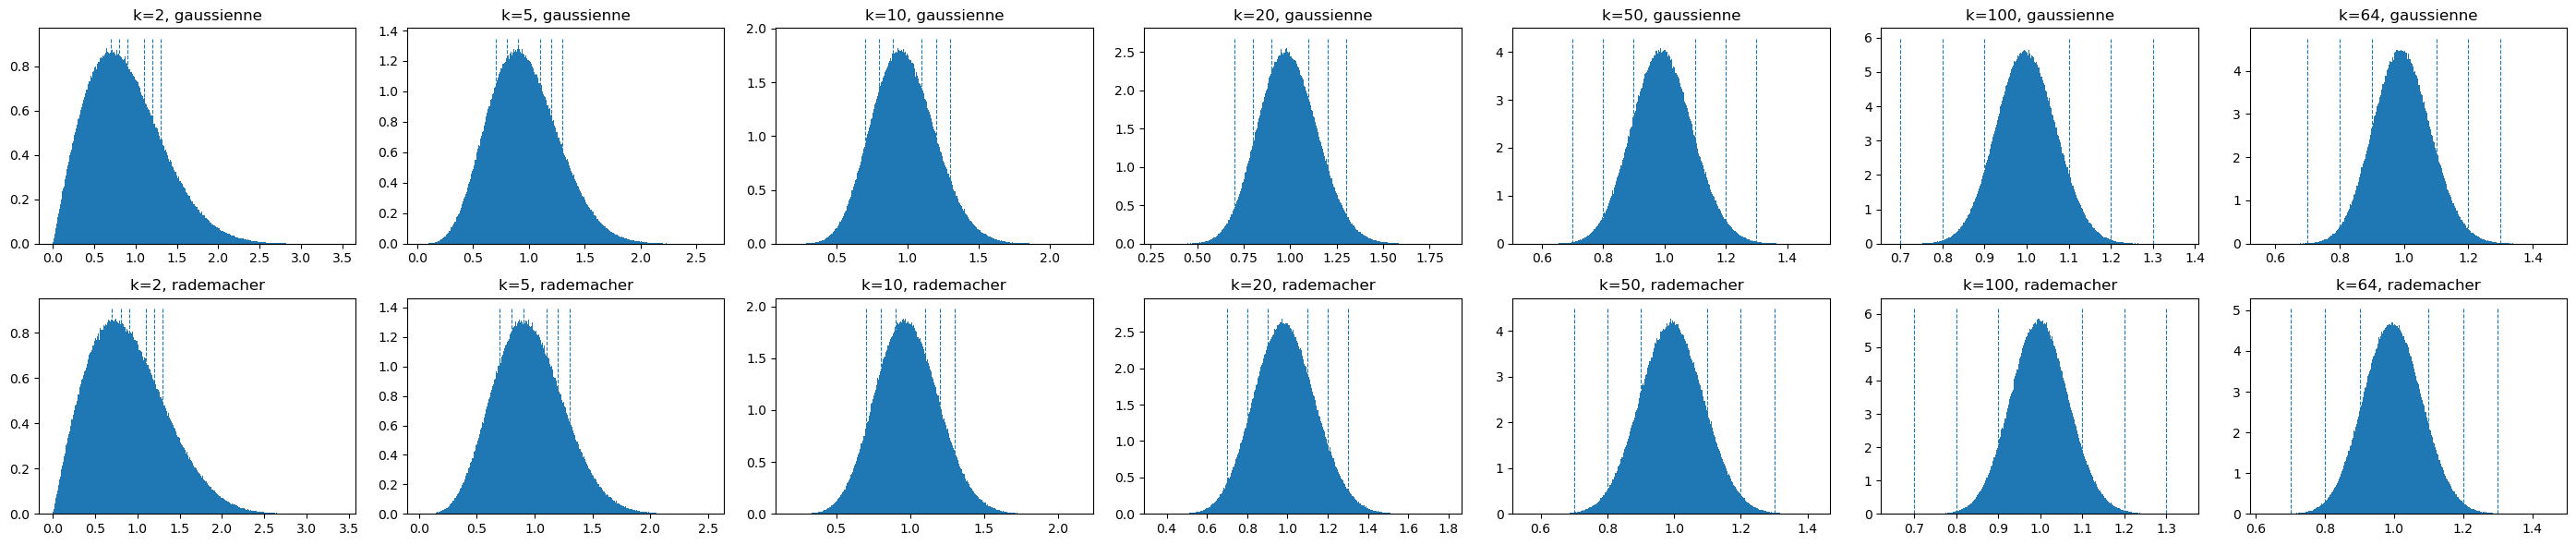

In [11]:
from sklearn.datasets import load_digits

# on charge digits et on sous-échantillonne m=200 points, qu'on normalise (x <- x/||x||)
digits = load_digits()
X_all = digits.data                  # (1797, 64)
n = X_all.shape[1]                   # dimension ambiante n = 64
m = 200

idx = npr.choice(X_all.shape[0], size=m, replace=False)
X = X_all[idx]
X = X / np.linalg.norm(X, axis=1, keepdims=True)

liste_k = [2, 5, 10, 20, 50, 100, n]
liste_eps = [0.1, 0.2, 0.3]
Rrep = 100     # nombre de tirages independants de Omega

# distances ||x_l - x_l'|| pour toutes les paires (l,l'), sous forme d'une matrice (m,m)
D_X = np.linalg.norm(X[:, np.newaxis, :] - X[np.newaxis, :, :], axis=-1)
mask = ~np.eye(m, dtype=bool)   # on retire la diagonale (l = l', distance nulle)

plt.figure(figsize=(4*len(liste_k), 6))

for j, k in enumerate(liste_k):
    for i, loi in enumerate(['gaussienne', 'rademacher']):

        # on repete Rrep fois le tirage de Omega et on empile tous les R(l,l') obtenus
        R_values = []
        for _ in range(Rrep):
            if loi == 'gaussienne':
                Omega = npr.randn(n, k)
            else:
                Omega = npr.choice([-1, 1], size=(n, k))   # loi de Rademacher

            Y = X @ Omega / np.sqrt(k)      # Y = P x pour chaque x
            D_Y = np.linalg.norm(Y[:, np.newaxis, :] - Y[np.newaxis, :, :], axis=-1)
            R_values.append(D_Y[mask] / D_X[mask])

        R_values = np.concatenate(R_values)

        # histogramme de la distribution de R(l,l')
        plt.subplot(2, len(liste_k), i*len(liste_k) + j + 1)
        plt.hist(R_values, bins='auto', density=True)
        ymax = plt.ylim()[1]
        for eps in liste_eps:
            plt.vlines([1-eps, 1+eps], 0, ymax, linestyles='dashed', linewidth=0.8)
        plt.title(f"k={k}, {loi}")

plt.tight_layout()
plt.show()

**Commentaire:** On observe que, pour les deux lois (gaussienne et Rademacher), la distribution de $R(\ell,\ell')$ se concentre de plus en plus étroitement autour de $1$ à mesure que $k$ augmente : pour les petites valeurs de $k$ (par exemple $k=2$), l'histogramme est très étalé et une part importante des paires sort des bandes $[1-\varepsilon,1+\varepsilon]$ même pour $\varepsilon=0.3$, tandis que pour $k$ grand (par exemple $k=100$ ou $k=n=64$), l'histogramme devient très resserré autour de $1$ et quasiment toutes les paires restent dans la bande $[1-0.1,1+0.1]$. Ceci illustre numériquement le résultat de T9 ($\mathbb{P}[|\|Y\|^2-1|\ge\varepsilon] \le 2e^{-k\varepsilon^2/8}$) : la probabilité de s'écarter de $1$ décroît exponentiellement vite avec $k$. On ne distingue par ailleurs pas de différence notable entre la loi gaussienne et la loi de Rademacher, ce qui est cohérent avec le fait que les deux lois vérifient les mêmes hypothèses de moments utilisées dans la preuve.


### S6. Probabilité d'échec empirique vs borne théorique

Pour chaque valeur de $k$, estimer empiriquement la probabilité d'échec
$$
\widehat p_{fail}(k,\varepsilon)=
\frac{\#\{(\ell,\ell') : |R(\ell,\ell')-1|>\varepsilon\}}
{\text{nombre total de paires}}.
$$
Tracer $\widehat p_{fail}$ en fonction de $k$ en échelle logarithmique pour $\varepsilon\in\{0.1,0.2,0.3\}$, et superposer la borne théorique
$$
p_{th}(k,\varepsilon)=m^2 e^{-k\varepsilon^2/8}.
$$
Commenter le caractère pessimiste de cette borne.


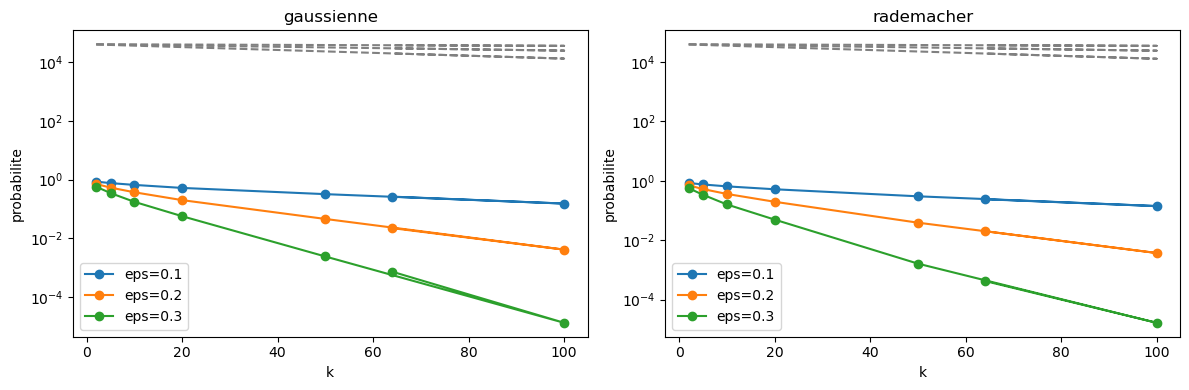

In [12]:

def normalise_lignes(X):
    # centrage puis normalisation de chaque vecteur
    X = X - np.mean(X, axis=1, keepdims=True)
    normes = np.linalg.norm(X, axis=1, keepdims=True)
    return X / normes


def calcule_R(X, k, loi='gaussienne', nb_rep=Rrep):
    # renvoie tous les rapports R(l,l') pour nb_rep projections independantes
    m_local, n_local = X.shape
    D_X = np.linalg.norm(X[:, np.newaxis, :] - X[np.newaxis, :, :], axis=-1)
    mask = D_X > 0

    valeurs_R = []
    for _ in range(nb_rep):
        if loi == 'gaussienne':
            Omega = npr.randn(n_local, k)
        else:
            Omega = npr.choice([-1, 1], size=(n_local, k))

        Y = X @ Omega / np.sqrt(k)
        D_Y = np.linalg.norm(Y[:, np.newaxis, :] - Y[np.newaxis, :, :], axis=-1)
        valeurs_R.append(D_Y[mask] / D_X[mask])

    return np.concatenate(valeurs_R)


X = normalise_lignes(X)
resultats_S6 = {}

plt.figure(figsize=(12, 4))
for i, loi in enumerate(['gaussienne', 'rademacher']):
    plt.subplot(1, 2, i+1)
    resultats_S6[loi] = {}

    for eps in liste_eps:
        p_fail = []
        for k in liste_k:
            R_valeurs = calcule_R(X, k, loi=loi)
            p_fail.append(np.mean(np.abs(R_valeurs - 1) > eps))

        borne = m**2 * np.exp(-np.array(liste_k) * eps**2 / 8)
        resultats_S6[loi][eps] = p_fail

        plt.plot(liste_k, p_fail, marker='o', label=f'eps={eps}')
        plt.plot(liste_k, borne, linestyle='dashed', color='gray')

    plt.yscale('log')
    plt.xlabel('k')
    plt.ylabel('probabilite')
    plt.title(loi)
    plt.legend()

plt.tight_layout()
plt.show()



La borne theorique reste au-dessus, mais elle est tres large : elle tient compte de toutes les paires en meme temps, donc elle est volontairement pessimiste.



### S7. Variance, biais et quantiles de $R$ en fonction de $k$

Sur le même jeu de données, calculer pour chaque $k$, en moyennant sur toutes les paires et les tirages :

- la variance empirique de $R(\ell,\ell')$ ;
- le biais $|\mathbb{E}[R(\ell,\ell')]-1|$ ;
- les quantiles à $5\%$ et $95\%$ de $R$.

Tracer ces trois quantités en fonction de $k$ sur un axe log-log, et vérifier visuellement la décroissance de la variance en $O(1/k)$.


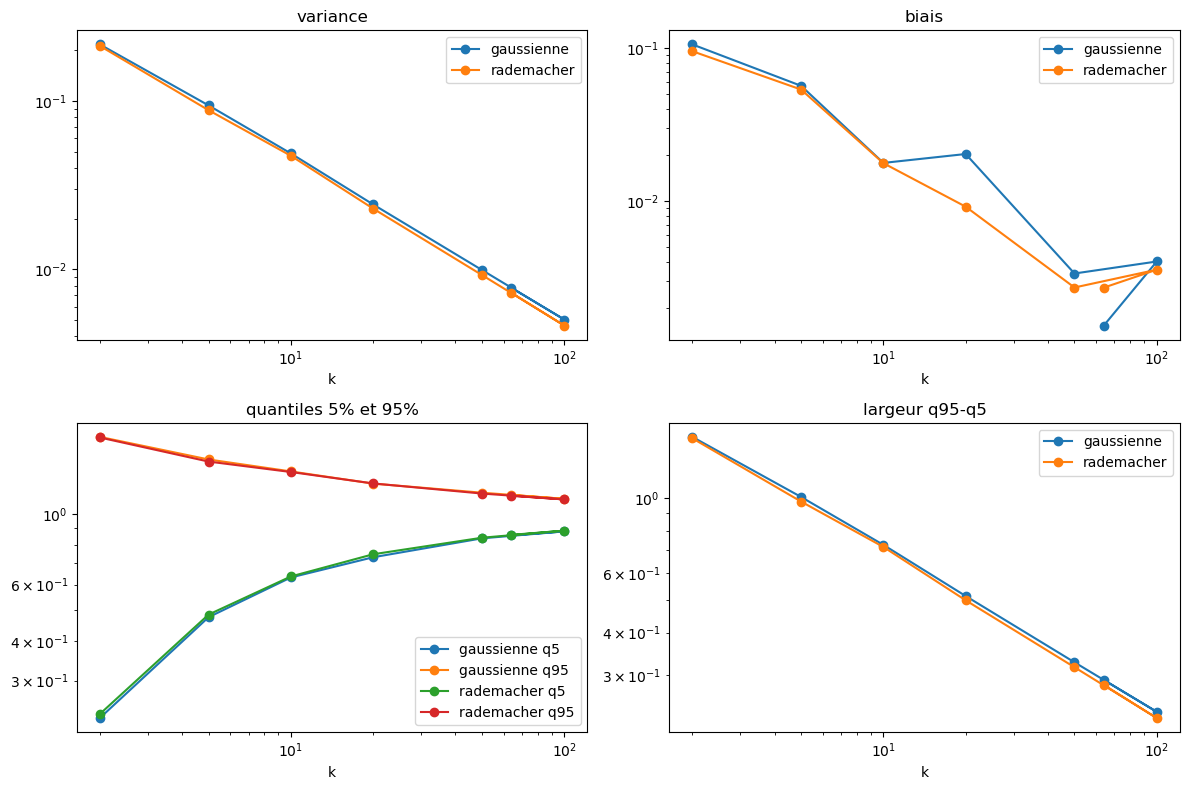

In [13]:

stats_S7 = {}

plt.figure(figsize=(12, 8))
for i, loi in enumerate(['gaussienne', 'rademacher']):
    variances = []
    biais = []
    q5 = []
    q95 = []

    for k in liste_k:
        R_valeurs = calcule_R(X, k, loi=loi)
        variances.append(np.var(R_valeurs))
        biais.append(abs(np.mean(R_valeurs) - 1))
        q5.append(np.quantile(R_valeurs, 0.05))
        q95.append(np.quantile(R_valeurs, 0.95))

    stats_S7[loi] = [variances, biais, q5, q95]

    plt.subplot(2, 2, 1)
    plt.plot(liste_k, variances, marker='o', label=loi)

    plt.subplot(2, 2, 2)
    plt.plot(liste_k, biais, marker='o', label=loi)

    plt.subplot(2, 2, 3)
    plt.plot(liste_k, q5, marker='o', label=f'{loi} q5')
    plt.plot(liste_k, q95, marker='o', label=f'{loi} q95')

    plt.subplot(2, 2, 4)
    largeur = np.array(q95) - np.array(q5)
    plt.plot(liste_k, largeur, marker='o', label=loi)

for numero, titre in enumerate(['variance', 'biais', 'quantiles 5% et 95%', 'largeur q95-q5'], start=1):
    plt.subplot(2, 2, numero)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('k')
    plt.title(titre)
    plt.legend()

plt.tight_layout()
plt.show()


Quand k augmente, la variance, le biais et la largeur entre les quantiles diminuent. La concentration autour de 1 devient donc de plus en plus nette.



### S8. Effet de la dimension ambiante $n$

Fixer $k=20$ et $m=200$. Utiliser `make_classification` avec $200$ points et un nombre de variables dans $\{10,50,100,200,500,1000\}$.

Tracer la variance empirique de $R$ et $\widehat p_{fail}$ en fonction de la dimension ambiante. Vérifier numériquement que la garantie de Johnson-Lindenstrauss dépend surtout de $k$ et pas directement de la dimension de départ.


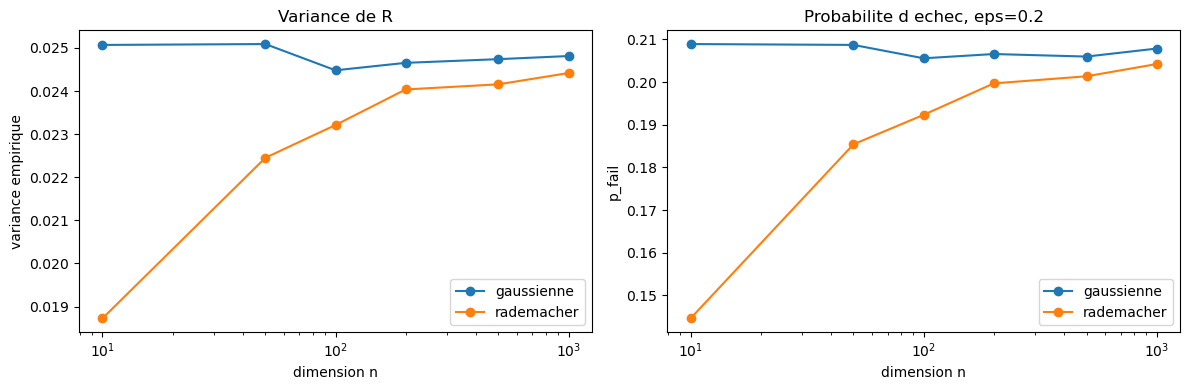

In [14]:

from sklearn.datasets import make_classification

k_fixe = 20
m_fixe = 200
eps = 0.2
liste_n = [10, 50, 100, 200, 500, 1000]

plt.figure(figsize=(12, 4))

for loi in ['gaussienne', 'rademacher']:
    liste_var = []
    liste_fail = []

    for n_dim in liste_n:
        X_sim, _ = make_classification(n_samples=m_fixe, n_features=n_dim,
                                       n_informative=max(2, n_dim//2),
                                       n_redundant=0, random_state=n_dim)
        X_sim = normalise_lignes(X_sim)
        R_valeurs = calcule_R(X_sim, k_fixe, loi=loi)

        liste_var.append(np.var(R_valeurs))
        liste_fail.append(np.mean(np.abs(R_valeurs - 1) > eps))

    plt.subplot(1, 2, 1)
    plt.plot(liste_n, liste_var, marker='o', label=loi)

    plt.subplot(1, 2, 2)
    plt.plot(liste_n, liste_fail, marker='o', label=loi)

plt.subplot(1, 2, 1)
plt.xscale('log')
plt.xlabel('dimension n')
plt.ylabel('variance empirique')
plt.title('Variance de R')
plt.legend()

plt.subplot(1, 2, 2)
plt.xscale('log')
plt.xlabel('dimension n')
plt.ylabel('p_fail')
plt.title('Probabilite d echec, eps=0.2')
plt.legend()

plt.tight_layout()
plt.show()



A k fixe, les courbes ne semblent pas exploser avec la dimension ambiante. C'est exactement l'idee du lemme : la dimension projetee necessaire depend surtout de eps, delta et du nombre de points.



### S9. Effet du nombre de points $m$

Fixer $k=30$ et $n=64$ avec le jeu de données `digits`. Faire varier $m\in\{10,20,50,100,200,500\}$.

1. Tracer $\widehat p_{fail}$ en fonction de $m$ et superposer la borne $m^2 e^{-k\varepsilon^2/8}$.
2. Déterminer empiriquement, pour chaque $m$, le plus petit $k^*(m)$ tel que $\widehat p_{fail}<0.05$ avec $\varepsilon=0.2$, puis comparer avec
$$
k_{th}(m)=\left\lceil \frac{8}{\varepsilon^2}(2\ln(m)-\ln(\delta))\right\rceil,
\quad \delta=0.05.
$$


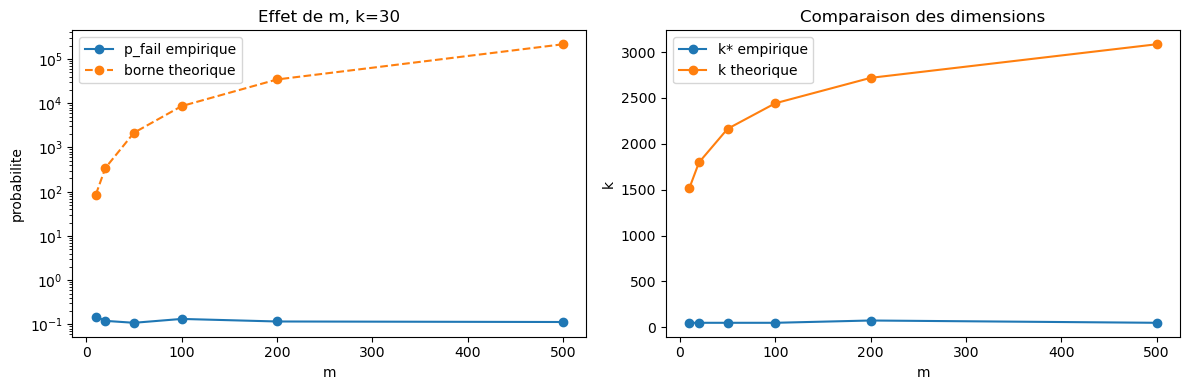

In [15]:
liste_m = [10, 20, 50, 100, 200, 500]
k_fixe = 30
eps = 0.2
delta = 0.05

# Version rapide : on garde toutes les valeurs de m, mais on reduit le nombre
# de repetitions pour eviter que la cellule tourne trop longtemps.
Rrep_S9 = 10
Rrep_recherche = 5
grille_k_test = [5, 10, 20, 30, 50, 75, 100, 150]

p_fail_gauss = []
borne_S9 = []
k_etoile = []
k_theorique = []

for m_test in liste_m:
    idx = npr.choice(X_all.shape[0], size=m_test, replace=False)
    X_test = normalise_lignes(X_all[idx])

    R_valeurs = calcule_R(X_test, k_fixe, loi='gaussienne', nb_rep=Rrep_S9)
    p_fail_gauss.append(np.mean(np.abs(R_valeurs - 1) > eps))
    borne_S9.append(m_test**2 * np.exp(-k_fixe * eps**2 / 8))

    k_trouve = np.nan
    for k_test in grille_k_test:
        R_valeurs = calcule_R(X_test, k_test, loi='gaussienne', nb_rep=Rrep_recherche)
        if np.mean(np.abs(R_valeurs - 1) > eps) < 0.05:
            k_trouve = k_test
            break

    k_etoile.append(k_trouve)
    k_theorique.append(int(np.ceil(8/eps**2 * (2*np.log(m_test) - np.log(delta)))))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(liste_m, p_fail_gauss, marker='o', label='p_fail empirique')
plt.plot(liste_m, borne_S9, marker='o', linestyle='dashed', label='borne theorique')
plt.yscale('log')
plt.xlabel('m')
plt.ylabel('probabilite')
plt.title('Effet de m, k=30')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(liste_m, k_etoile, marker='o', label='k* empirique')
plt.plot(liste_m, k_theorique, marker='o', label='k theorique')
plt.xlabel('m')
plt.ylabel('k')
plt.title('Comparaison des dimensions')
plt.legend()

plt.tight_layout()
plt.show()


**Commentaire S9.** La borne théorique augmente avec $m^2$ dans la probabilité d'échec, puis donne une dimension théorique $k_{th}(m)$ qui croît comme $\frac{1}{\varepsilon^2}\ln(m)$. En pratique, la dimension empirique $k^*(m)$ est souvent beaucoup plus petite que la borne théorique car la borne de Johnson-Lindenstrauss est uniforme sur toutes les paires et volontairement prudente.



### S10. Comparaison Gaussien vs Rademacher

Sur les quatre jeux de données (`digits`, `olivetti_faces`, `covtype`, `make_classification`), pour chaque valeur de $k$, produire :

- un boxplot côte-à-côte de $R(\ell,\ell')$ pour les deux lois ;
- le rapport $\mathrm{Var}(R,\mathrm{Gaussien})/\mathrm{Var}(R,\mathrm{Rademacher})$ en fonction de $k$ ;
- $\widehat p_{fail}$ pour les deux lois sur le même graphe.

Conclure sur les régimes où la loi de Rademacher offre un avantage mesurable par rapport à la loi gaussienne.


/tmp/ipykernel_1187512/2225228207.py:71: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=box_k, showfliers=False)


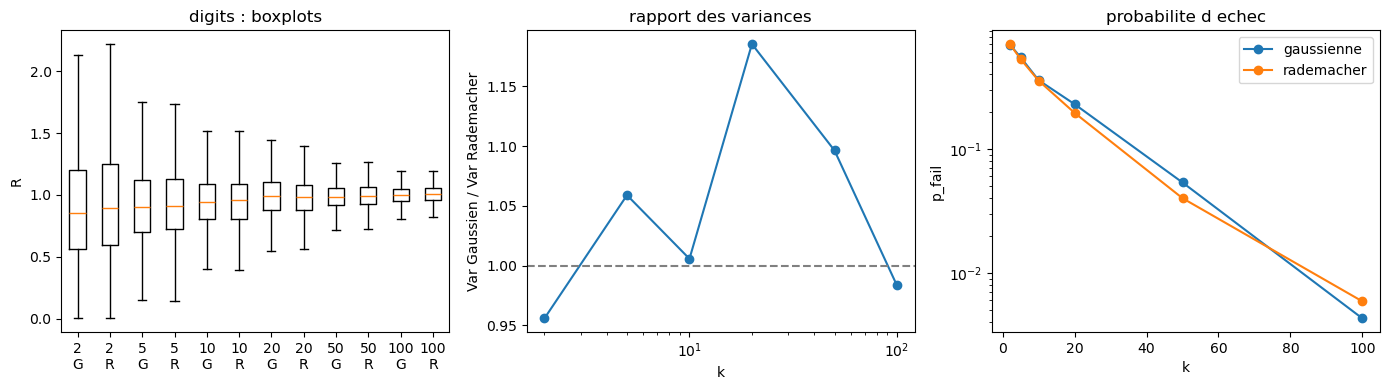

/tmp/ipykernel_1187512/2225228207.py:71: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=box_k, showfliers=False)


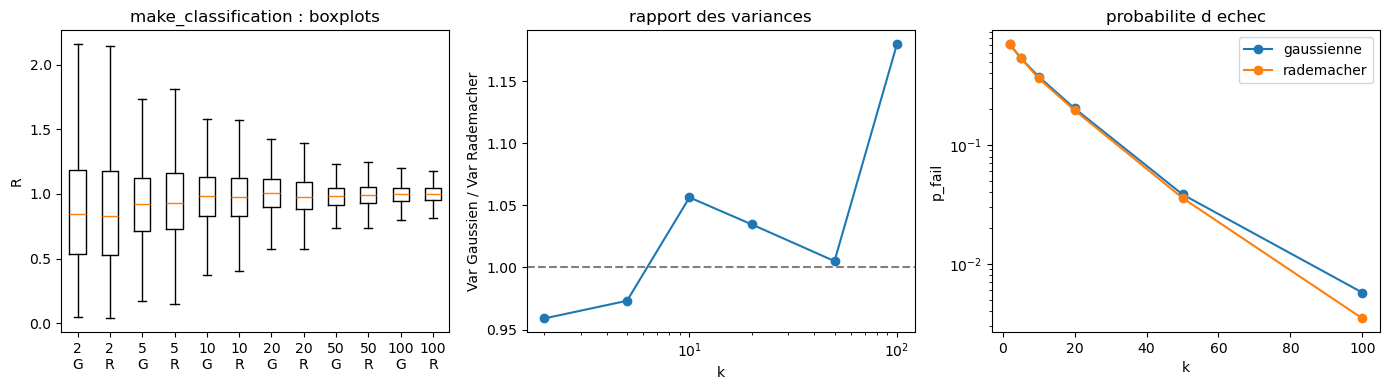

/tmp/ipykernel_1187512/2225228207.py:71: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=box_k, showfliers=False)


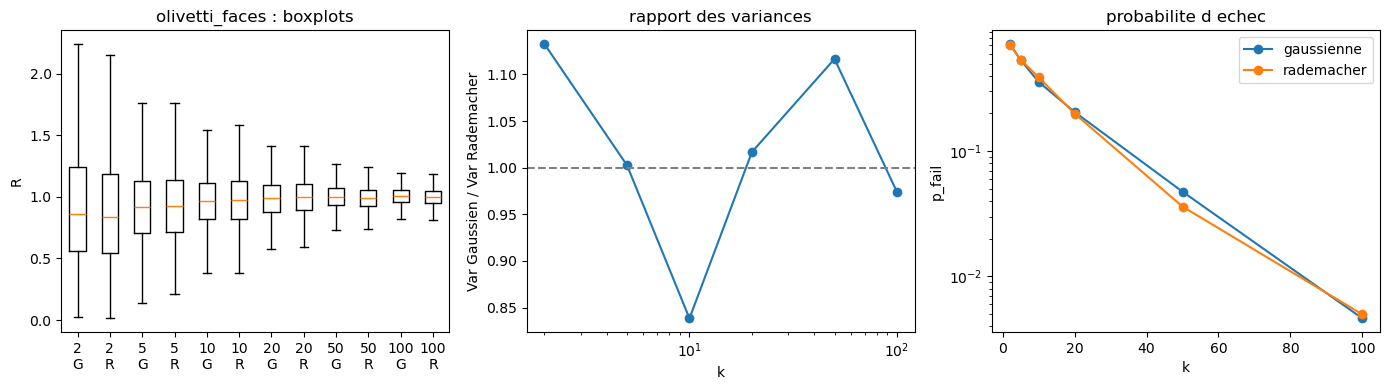

/tmp/ipykernel_1187512/2225228207.py:71: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=box_k, showfliers=False)


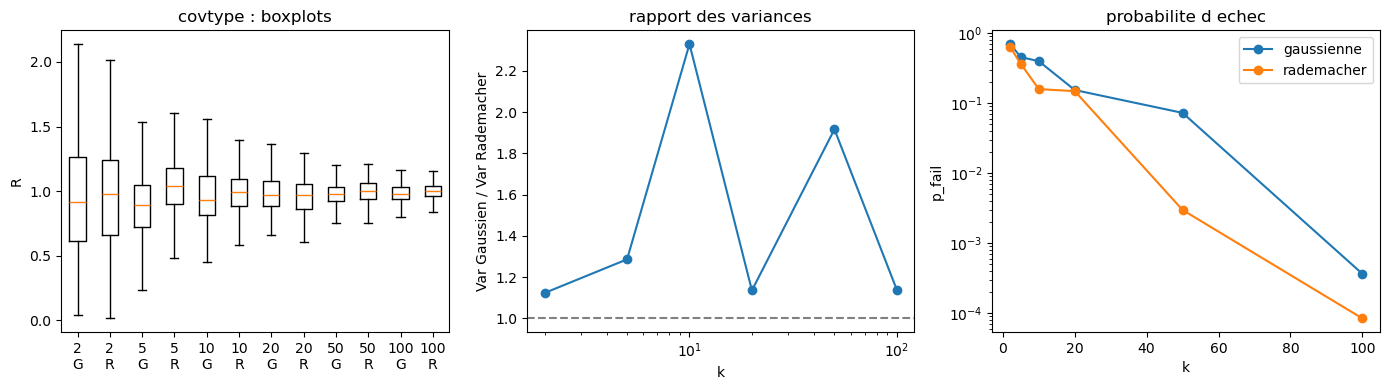

In [16]:
from sklearn.datasets import fetch_olivetti_faces, fetch_covtype


def prend_lignes(X, nb_lignes):
    if X.shape[0] <= nb_lignes:
        return X
    idx = npr.choice(X.shape[0], size=nb_lignes, replace=False)
    return X[idx]


def sous_echantillon(valeurs, taille=3000):
    # seulement pour alleger les boxplots : les statistiques sont calculees avant
    if len(valeurs) <= taille:
        return valeurs
    idx = npr.choice(len(valeurs), size=taille, replace=False)
    return valeurs[idx]


def prepare_jeux_donnees_rapide(nb_points=120):
    jeux = {}

    idx = npr.choice(X_all.shape[0], size=nb_points, replace=False)
    jeux['digits'] = normalise_lignes(X_all[idx])

    X_mc, _ = make_classification(n_samples=nb_points, n_features=64,
                                  n_informative=32, n_redundant=0,
                                  random_state=123)
    jeux['make_classification'] = normalise_lignes(X_mc)

    try:
        oli = fetch_olivetti_faces(shuffle=True, random_state=123, download_if_missing=False)
        jeux['olivetti_faces'] = normalise_lignes(prend_lignes(oli.data, nb_points))
    except Exception as erreur:
        print('olivetti_faces non disponible localement :', erreur)

    try:
        cov = fetch_covtype(shuffle=True, random_state=123, download_if_missing=False)
        jeux['covtype'] = normalise_lignes(prend_lignes(cov.data, nb_points))
    except Exception as erreur:
        print('covtype non disponible localement :', erreur)

    return jeux


jeux = prepare_jeux_donnees_rapide(nb_points=120)
liste_k_S10 = [2, 5, 10, 20, 50, 100]
eps = 0.2
Rrep_S10 = 10

for nom, X_data in jeux.items():
    rapports_var = []
    p_fail_g = []
    p_fail_r = []
    box_k = []
    box_data = []

    for k in liste_k_S10:
        R_g = calcule_R(X_data, k, loi='gaussienne', nb_rep=Rrep_S10)
        R_r = calcule_R(X_data, k, loi='rademacher', nb_rep=Rrep_S10)

        rapports_var.append(np.var(R_g) / np.var(R_r))
        p_fail_g.append(np.mean(np.abs(R_g - 1) > eps))
        p_fail_r.append(np.mean(np.abs(R_r - 1) > eps))

        box_k += [f'{k}\nG', f'{k}\nR']
        box_data += [sous_echantillon(R_g), sous_echantillon(R_r)]

    plt.figure(figsize=(14, 4))

    plt.subplot(1, 3, 1)
    plt.boxplot(box_data, labels=box_k, showfliers=False)
    plt.title(nom + ' : boxplots')
    plt.ylabel('R')

    plt.subplot(1, 3, 2)
    plt.plot(liste_k_S10, rapports_var, marker='o')
    plt.axhline(1, color='gray', linestyle='dashed')
    plt.xscale('log')
    plt.xlabel('k')
    plt.ylabel('Var Gaussien / Var Rademacher')
    plt.title('rapport des variances')

    plt.subplot(1, 3, 3)
    plt.plot(liste_k_S10, p_fail_g, marker='o', label='gaussienne')
    plt.plot(liste_k_S10, p_fail_r, marker='o', label='rademacher')
    plt.yscale('log')
    plt.xlabel('k')
    plt.ylabel('p_fail')
    plt.title('probabilite d echec')
    plt.legend()

    plt.tight_layout()
    plt.show()


**Commentaire S10.** Les deux lois donnent généralement des résultats très proches : les boxplots se resserrent lorsque $k$ augmente, et la probabilité d'échec diminue pour les deux projections. La loi de Rademacher peut parfois avoir une variance ou une probabilité d'échec légèrement plus faible, mais l'avantage dépend du jeu de données et n'est pas systématique. Ici on sous-échantillonne les jeux de données et les valeurs affichées dans les boxplots pour que la comparaison reste rapide à exécuter.
